# 2D U-Net ornament segmentation (ROD + PB)

What this notebook does, step by step:

1. **GPU check**: uses the laptop GPU through the local runtime. If no GPU is visible it stops with an error. It never switches to the CPU.
2. **Cached data only**: loads the saved ROD CQT features and PB constant-Q features, the frame labels, the segments and the original train / validation / test splits from `rod_koopman/cache/`. Nothing is downloaded, separated or re-extracted.
3. **Preprocessing**: removes silence only at the **start and end** of each recording, then applies per-frequency-bin normalisation (statistics from the training recordings only).
4. **Model**: a small 2D U-Net that reads the whole CQT of a recording and predicts one of 7 classes (`none, K, H, Me, G, Mu, An`) for every time frame.
5. **Training**: plain cross-entropy loss (no class weights, no augmentation), one full recording per step.
6. **Hyperparameter search**: changes one group of settings at a time, starting from the small U-Net, and keeps the change only if validation F1 improves. The test set is not used here.
7. **Test evaluation**: the selected model is evaluated once on the held-out test recordings.

## 1. GPU runtime check

In [1]:
import os, sys, time, json, math, random, pickle, gc
from pathlib import Path
from collections import Counter
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from IPython.display import display

print('python :', sys.executable)
print('torch  :', torch.__version__, '| CUDA build:', torch.version.cuda)
if not torch.cuda.is_available():
    raise RuntimeError('No CUDA GPU is visible to PyTorch in this kernel. Stopping instead of falling back to the CPU. '
                       'Check that the notebook is connected to the local runtime that has the CUDA build of torch.')
DEV = torch.device('cuda:0')
_p = torch.cuda.get_device_properties(0)
_free, _total = torch.cuda.mem_get_info()
print(f'GPU    : {_p.name} | {_total / 2**30:.2f} GiB total, {_free / 2**30:.2f} GiB free | compute capability {_p.major}.{_p.minor}')
# Recordings have different lengths. cuDNN autotuning would re-benchmark for every new length (very slow), so it is off.
torch.backends.cudnn.benchmark = False
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True
AMP_DTYPE = torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16
print('mixed precision dtype:', AMP_DTYPE)
_a = torch.randn(1024, 1024, device=DEV); _ = float((_a @ _a).sum()); del _a
print('GPU compute check OK')

SEED = 2035
def seed_all(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

python : C:\Users\YOGESH KRISHNA\Desktop\proj\Environments\jupy-env\Scripts\python.exe
torch  : 2.14.1+cu130 | CUDA build: 13.0
GPU    : NVIDIA GeForce RTX 3050 A Laptop GPU | 4.00 GiB total, 3.17 GiB free | compute capability 8.9
mixed precision dtype: torch.bfloat16
GPU compute check OK


## 2. Load the cached features, labels and splits

In [2]:
PROJ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'rod_koopman' / 'cache').is_dir())
CACHE = PROJ / 'rod_koopman' / 'cache'
OUT = PROJ / 'rod_koopman' / 'unet_seg'; OUT.mkdir(exist_ok=True)
RUNS = OUT / 'runs'; RUNS.mkdir(exist_ok=True)
print('cache :', CACHE); print('output:', OUT)

CLASSES = ['none', 'K', 'H', 'Me', 'G', 'Mu', 'An']   # 0 = no ornament
C2I = {c: i for i, c in enumerate(CLASSES)}; NC = len(CLASSES); IGNORE = -100
SPLITS = ('train', 'val', 'test')

KEEP = ('id', 'dataset', 'audio', 'x', 'fps', 'segs', 'y', 'dur', 'split')
RAW = {}
for name in ('ROD', 'PB'):
    t0 = time.time()
    RAW[name] = [{k: t[k] for k in KEEP if k in t} for t in pickle.loads((CACHE / f'{name}_tracks.pkl').read_bytes())]
    tr = RAW[name]
    print(f"{name}: {len(tr)} recordings | {tr[0]['x'].shape[1]} constant-Q bins @ {tr[0]['fps']} frames/s "
          f"| loaded in {time.time() - t0:.1f}s")

cache : C:\Users\YOGESH KRISHNA\Desktop\smai-project\rod_koopman\cache
output: C:\Users\YOGESH KRISHNA\Desktop\smai-project\rod_koopman\unet_seg
ROD: 204 recordings | 216 constant-Q bins @ 100.0 frames/s | loaded in 0.5s
PB: 42 recordings | 141 constant-Q bins @ 56.8 frames/s | loaded in 0.0s


In [3]:
# ---- integrity checks (the cached splits are used exactly as they are) ----
def check(tracks, name):
    ids = {s: {t['id'] for t in tracks if t['split'] == s} for s in SPLITS}
    assert not (ids['train'] & ids['val']) and not (ids['train'] & ids['test']) and not (ids['val'] & ids['test'])
    if 'audio' in tracks[0]:                       # the same recording is never in two splits
        rec = {}
        for t in tracks:
            rec.setdefault(os.path.basename(t['audio']), set()).add(t['split'])
        assert all(len(v) == 1 for v in rec.values()), 'a recording appears in more than one split'
    bad = tot = 0                                  # frame labels agree with the segment list
    for t in tracks:
        assert len(t['x']) == len(t['y'])
        for s, e, l in t['segs']:
            if l is None: continue
            i = min(int((s + e) / 2 * t['fps']), len(t['y']) - 1); tot += 1; bad += int(t['y'][i] != C2I[l])
    assert bad <= 0.01 * tot, f'{bad} label mismatches'
    print(f'{name}: splits disjoint, {tot - bad}/{tot} labelled segments consistent with the frame labels '
          f'({bad} nested inside another annotation)')
    return bad

def summary(tracks):
    rows = []
    for s in SPLITS:
        ts = [t for t in tracks if t['split'] == s]
        y = np.concatenate([t['y'] for t in ts]); n = Counter(l for t in ts for *_, l in t['segs'] if l)
        rows.append(dict(split=s, recordings=len(ts), minutes=round(sum(t['dur'] for t in ts) / 60, 1),
                         ornament_frames=round(float(np.mean(y[y != IGNORE] > 0)), 3), **{c: n.get(c, 0) for c in CLASSES[1:]}))
    return pd.DataFrame(rows).set_index('split')

BAD_RAW = {}
for name in RAW:
    BAD_RAW[name] = check(RAW[name], name); display(summary(RAW[name]))

ROD: splits disjoint, 3894/3894 labelled segments consistent with the frame labels (0 nested inside another annotation)


,recordings,minutes,ornament_frames,K,H,Me,G,Mu,An
split,,,,,,,,,
train,137,90.5,0.358,657,1090,710,70,24,20
val,24,14.6,0.367,95,154,113,11,18,11
test,43,35.1,0.338,241,360,256,24,24,16


PB: splits disjoint, 409/410 labelled segments consistent with the frame labels (1 nested inside another annotation)


,recordings,minutes,ornament_frames,K,H,Me,G,Mu,An
split,,,,,,,,,
train,30,15.1,0.413,78,72,56,54,19,12
val,6,3.0,0.428,17,7,4,17,2,3
test,6,3.0,0.410,19,21,14,7,6,2


## 3. Preprocessing step: remove silence at the start and end of each recording

Many recordings begin (and some end) with several seconds of silence. This step removes **only** that leading and trailing silence. Nothing is removed from the middle of a recording.

How it works, for each recording:

* **Loudness of each frame** = the loudest constant-Q bin in that frame, in dB. ROD features are already in dB; PB magnitudes are converted with $20\log_{10}$.
* **Reference level** = the 95th percentile of the frame loudness, i.e. the typical loud level of that recording.
* A frame counts as **sound** if it is at most 40 dB below the reference level. Quiet notes are rarely this far down: in ROD only 0.07% of ornament frames are.
* The recording is cut just before the first sound frame and just after the last one, keeping a **0.2 s safety margin** on each side.
* **Safety rule**: the cut never reaches into an annotated segment or a labelled frame. If an annotation starts earlier than the detected sound, the cut moves back to keep it (plus the margin). Edge silences shorter than 0.5 s are left alone.
* The features `x` and the frame labels `y` are cut with the same frame indices. Segment timestamps are shifted by the same amount (`start_frame / fps`), so all three stay aligned. The same method is applied to train, validation and test.

In [4]:
SIL_DB, MARGIN_S, MIN_TRIM_S = 40.0, 0.2, 0.5

def loudness_db(t):
    e = t['x'].max(1).astype(np.float64)
    return e if t['dataset'] == 'ROD' else 20 * np.log10(e + 1e-5)

def trim_edges(t):
    fps, T = t['fps'], len(t['y'])
    e = loudness_db(t); ref = np.percentile(e, 95)
    m = int(round(MARGIN_S * fps))
    sound = np.flatnonzero(e >= ref - SIL_DB)
    a, b = (max(0, sound[0] - m), min(T, sound[-1] + 1 + m)) if len(sound) else (0, T)
    lab = np.flatnonzero(t['y'] != 0)                          # ornament (or ignored) frames are never removed
    times = [v for s, e_, _ in t['segs'] for v in (s, e_)]       # nor any annotated segment
    if len(lab): a, b = min(a, max(0, lab[0] - m)), max(b, min(T, lab[-1] + 1 + m))
    if times: a, b = min(a, max(0, int(np.floor(min(times) * fps)) - m)), max(b, min(T, int(np.ceil(max(times) * fps)) + m))
    if a < MIN_TRIM_S * fps: a = 0
    if T - b < MIN_TRIM_S * fps: b = T
    off = a / fps
    new = dict(t, x=t['x'][a:b], y=t['y'][a:b], segs=[(s - off, e_ - off, l) for s, e_, l in t['segs']],
               dur=(b - a) / fps, trim=(int(a), int(b), int(T)), ref_db=float(ref))
    # ---- alignment checks ----
    assert (t['y'][:a] == 0).all() and (t['y'][b:] == 0).all(), 'a labelled frame would be removed'
    assert all(-1e-6 <= s and e_ <= new['dur'] + 1e-6 for s, e_, _ in new['segs']), 'a segment falls outside the trimmed recording'
    for (s0, e0, l), (s1, e1, _) in zip(t['segs'], new['segs']):   # same label at every segment's midpoint
        i0 = min(int((s0 + e0) / 2 * fps), T - 1); i1 = min(int((s1 + e1) / 2 * fps), b - a - 1)
        assert t['y'][i0] == new['y'][i1]
    return new

D = {name: [trim_edges(t) for t in RAW[name]] for name in RAW}
for name in D:                                   # the whole integrity check again, on the trimmed data
    assert check(D[name], name + ' (after trimming)') == BAD_RAW[name]

rows = []
for name in D:
    for s in SPLITS:
        ts = [t for t in D[name] if t['split'] == s]
        lead = np.array([t['trim'][0] for t in ts]) / ts[0]['fps']; tail = np.array([t['trim'][2] - t['trim'][1] for t in ts]) / ts[0]['fps']
        tot = sum(t['trim'][2] for t in ts) / ts[0]['fps']
        rows.append(dict(dataset=name, split=s, recordings=len(ts), trimmed_recordings=int(np.sum((lead > 0) | (tail > 0))),
                         lead_removed_s_total=lead.sum().round(1), tail_removed_s_total=tail.sum().round(1),
                         lead_removed_s_max=lead.max().round(1), percent_of_audio_removed=round(100 * (lead.sum() + tail.sum()) / tot, 1)))
display(pd.DataFrame(rows).set_index(['dataset', 'split']))
for name in D: display(summary(D[name]).rename_axis(f'{name} after trimming'))

ROD (after trimming): splits disjoint, 3894/3894 labelled segments consistent with the frame labels (0 nested inside another annotation)
PB (after trimming): splits disjoint, 409/410 labelled segments consistent with the frame labels (1 nested inside another annotation)


recordings  trimmed_recordings  lead_removed_s_total  \
dataset split                                                         
ROD     train         137                 105                 709.0   
        val            24                  20                 136.8   
        test           43                  33                 231.8   
PB      train          30                   7                  22.0   
        val             6                   0                   0.0   
        test            6                   1                   0.0   

               tail_removed_s_total  lead_removed_s_max  \
dataset split                                             
ROD     train                  39.1                21.4   
        val                     8.3                17.5   
        test                   13.1                17.5   
PB      train                   5.7                 9.2   
        val                     0.0                 0.0   
        test                    2.1                 0.0   

               percent_of_audio_removed  
dataset split                            
ROD     train                      13.8  
        val                        16.5  
        test                       11.6  
PB      train                       3.1  
        val                         0.0  
        test                        1.2

,recordings,minutes,ornament_frames,K,H,Me,G,Mu,An
ROD after trimming,,,,,,,,,
train,137,78.0,0.415,657,1090,710,70,24,20
val,24,12.2,0.440,95,154,113,11,18,11
test,43,31.1,0.383,241,360,256,24,24,16


,recordings,minutes,ornament_frames,K,H,Me,G,Mu,An
PB after trimming,,,,,,,,,
train,30,14.6,0.426,78,72,56,54,19,12
val,6,3.0,0.428,17,7,4,17,2,3
test,6,3.0,0.414,19,21,14,7,6,2


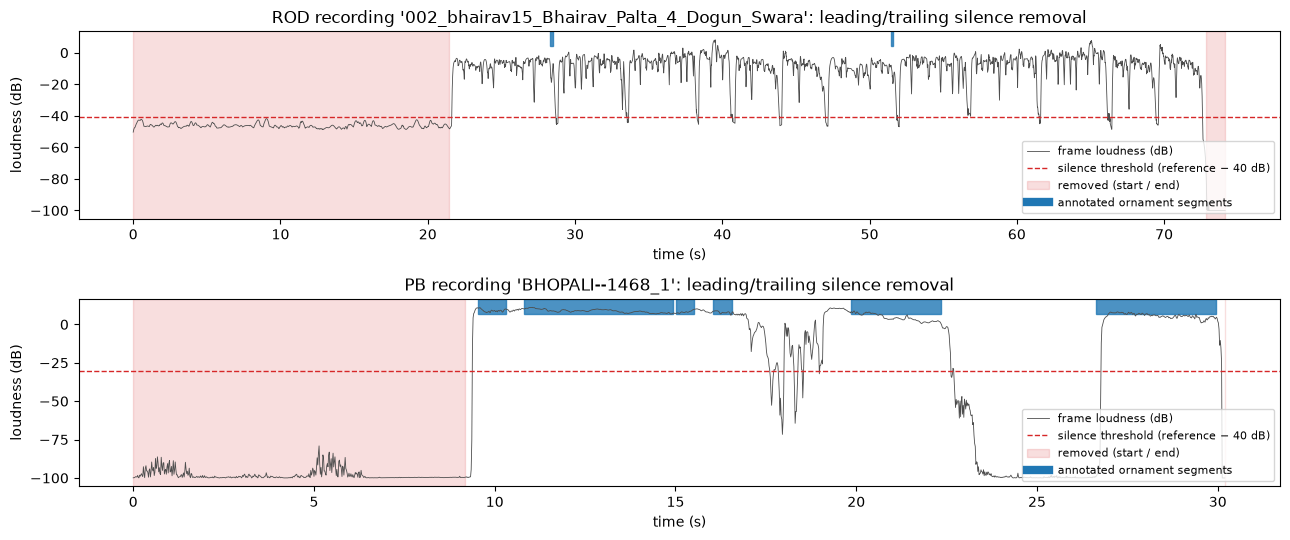

In [5]:
# ---- what the trimming does on two example recordings ----
fig, axes = plt.subplots(2, 1, figsize=(13, 5.5))
for ax, name in zip(axes, ('ROD', 'PB')):
    t = max(RAW[name], key=lambda r: [x for x in D[name] if x['id'] == r['id']][0]['trim'][0])   # most leading silence
    tt = next(x for x in D[name] if x['id'] == t['id']); a, b, T = tt['trim']; fps = t['fps']
    e = loudness_db(t); time_s = np.arange(T) / fps
    ax.plot(time_s, e, lw=0.6, color='0.3', label='frame loudness (dB)')
    ax.axhline(tt['ref_db'] - SIL_DB, color='tab:red', ls='--', lw=1, label=f'silence threshold (reference − {SIL_DB:.0f} dB)')
    ax.axvspan(0, a / fps, color='tab:red', alpha=0.15, label='removed (start / end)')
    ax.axvspan(b / fps, T / fps, color='tab:red', alpha=0.15)
    for s, e_, l in t['segs']:
        if l: ax.axvspan(s, e_, ymin=0.92, ymax=1.0, color='tab:blue', alpha=0.8)
    ax.plot([], [], color='tab:blue', lw=6, label='annotated ornament segments')
    ax.set(title=f"{name} recording '{t['id']}': leading/trailing silence removal", xlabel='time (s)', ylabel='loudness (dB)')
    ax.legend(loc='lower right', fontsize=8)
plt.tight_layout(); plt.show()

## 4. Normalisation

Every constant-Q bin is standardised to zero mean and unit variance. The mean and standard deviation come from the **trimmed training recordings only**, separately for ROD and PB, and the same statistics are applied to validation and test. Nothing else is done to the features: no augmentation, no frequency masking, no extra features.

In [6]:
class SegData:
    def __init__(s, tracks):
        s.name, s.fps = tracks[0]['dataset'], float(tracks[0]['fps'])
        s.tracks = {sp: [t for t in tracks if t['split'] == sp] for sp in SPLITS}
        X = np.concatenate([t['x'] for t in s.tracks['train']]).astype(np.float64)
        s.mu, s.sd = X.mean(0).astype(np.float32), (X.std(0) + 1e-5).astype(np.float32)
        s.n_feat = X.shape[1]
        # (freq, time) per recording, kept on the CPU and copied to the GPU one recording at a time
        s.x = {t['id']: torch.from_numpy(((t['x'] - s.mu) / s.sd).T.astype(np.float16).copy()) for t in tracks}
        s.y = {t['id']: torch.from_numpy(t['y'].astype(np.int64)) for t in tracks}
        s.longest = {sp: max(ts, key=lambda t: len(t['y'])) for sp, ts in s.tracks.items()}

    def get(s, t):     # -> x: (1, 1, F, T) float32, y: (1, T)
        return s.x[t['id']].to(DEV, non_blocking=True).float()[None, None], s.y[t['id']].to(DEV)[None]

DATA = {name: SegData(D[name]) for name in D}
for name, d in DATA.items():
    xtr = torch.cat([d.x[t['id']].float() for t in d.tracks['train']], 1)
    print(f"{name}: train-normalised features mean {xtr.mean():.3f}, std {xtr.std():.3f} | longest recording per split (frames): "
          + ', '.join(f"{sp}={len(d.longest[sp]['y'])}" for sp in SPLITS))
del xtr

ROD: train-normalised features mean 0.000, std 1.000 | longest recording per split (frames): train=15363, val=9649, test=15370
PB: train-normalised features mean -0.000, std 1.000 | longest recording per split (frames): train=1716, val=1716, test=1716


## 5. Evaluation metrics

Predicted segments are the runs of a single ornament class in the raw per-frame argmax predictions (no post-processing). Each predicted segment is matched one-to-one (greedy, by IoU) to a ground-truth segment **of the same class** with temporal IoU ≥ 0.5.

* **Precision** = matched / predicted segments, **Recall** = matched / ground-truth segments, **F1** = their harmonic mean. This segment F1 is the number used to choose models.
* **IoU**: frame-level IoU per ornament class, macro-averaged (`IoU_macro`); ornament-vs-none IoU (`IoU_orn`); mean IoU of the matched segments (`IoU_matched`).
* **Segment-level accuracy** = TP / (TP + FP + FN). A segment counts as correct only if its class and its extent (IoU ≥ 0.5) are both right. Missed and spurious segments both count as errors.
* **Per-class**: segment-level P / R / F1 for each ornament class, and frame-level P / R / F1 / IoU for all 7 classes (including `none`).

In [7]:
def runs(lab):
    lab = np.asarray(lab)
    if len(lab) == 0: return []
    ch = np.flatnonzero(np.diff(lab)) + 1
    st, en = np.r_[0, ch], np.r_[ch, len(lab)]
    return [(int(a), int(b), int(lab[a])) for a, b in zip(st, en) if lab[a] > 0]

def match(pred, gt, thr, class_aware=True):
    if not pred or not gt: return []
    P, G = np.array(pred, float), np.array(gt, float)
    inter = np.clip(np.minimum(P[:, None, 1], G[None, :, 1]) - np.maximum(P[:, None, 0], G[None, :, 0]), 0, None)
    union = np.maximum(P[:, None, 1], G[None, :, 1]) - np.minimum(P[:, None, 0], G[None, :, 0])
    iou = inter / np.maximum(union, 1e-9)
    if class_aware: iou = np.where(P[:, None, 2] == G[None, :, 2], iou, 0.0)
    ii, jj = np.nonzero(iou >= thr)
    used_p, used_g, pairs = set(), set(), []
    for k in np.argsort(-iou[ii, jj], kind='stable'):
        i, j = int(ii[k]), int(jj[k])
        if i not in used_p and j not in used_g:
            used_p.add(i); used_g.add(j); pairs.append((i, j, float(iou[i, j])))
    return pairs

def evaluate(labs, tracks, thr=0.5, tol=0.1):
    tp = tp_any = tp30 = n_pred = n_gt = n_bnd = 0
    ious, inter, union = [], np.zeros(NC), np.zeros(NC)
    i_orn = u_orn = corr = n_valid = 0
    c_tp, c_np, c_ng = np.zeros(NC), np.zeros(NC), np.zeros(NC)
    for t in tracks:
        lab, y, fps = labs[t['id']], t['y'], t['fps']
        valid = y != IGNORE
        pred = [(s / fps, e / fps, c) for s, e, c in runs(np.where(valid, lab, 0))]
        gt = [(s, e, C2I[l]) for s, e, l in t['segs'] if l is not None]
        pairs = match(pred, gt, thr)
        tp += len(pairs); n_pred += len(pred); n_gt += len(gt)
        tp_any += len(match(pred, gt, thr, class_aware=False)); tp30 += len(match(pred, gt, 0.3))
        ious += [p[2] for p in pairs]
        n_bnd += sum(abs(pred[i][0] - gt[j][0]) <= tol and abs(pred[i][1] - gt[j][1]) <= tol for i, j, _ in pairs)
        for i, j, _ in pairs: c_tp[gt[j][2]] += 1
        for p in pred: c_np[p[2]] += 1
        for g in gt: c_ng[g[2]] += 1
        lv, yv = lab[valid], y[valid]
        for c in range(1, NC):
            inter[c] += np.sum((lv == c) & (yv == c)); union[c] += np.sum((lv == c) | (yv == c))
        i_orn += np.sum((lv > 0) & (yv > 0)); u_orn += np.sum((lv > 0) | (yv > 0))
        corr += np.sum(lv == yv); n_valid += len(yv)
    f1 = lambda a, b: 2 * a * b / max(a + b, 1e-9)
    P, R = tp / max(n_pred, 1), tp / max(n_gt, 1)
    Pa, Ra = tp_any / max(n_pred, 1), tp_any / max(n_gt, 1)
    present = [c for c in range(1, NC) if c_ng[c] > 0]
    out = dict(P=P, R=R, F1=f1(P, R), F1_any=f1(Pa, Ra), F1_iou30=f1(tp30 / max(n_pred, 1), tp30 / max(n_gt, 1)),
               IoU_macro=float(np.mean([inter[c] / max(union[c], 1) for c in present])),
               IoU_orn=i_orn / max(u_orn, 1), IoU_matched=float(np.mean(ious)) if ious else 0.0,
               seg_acc=tp / max(n_pred + n_gt - tp, 1), boundary_acc=n_bnd / max(n_gt, 1),
               frame_acc=corr / max(n_valid, 1), n_pred=n_pred, n_gt=n_gt)
    per_class = {CLASSES[c]: dict(P=c_tp[c] / max(c_np[c], 1), R=c_tp[c] / c_ng[c],
                                  F1=f1(c_tp[c] / max(c_np[c], 1), c_tp[c] / c_ng[c]),
                                  IoU=inter[c] / max(union[c], 1), n_gt=int(c_ng[c]), n_pred=int(c_np[c])) for c in present}
    return out, per_class

def frame_report(labs, tracks):
    cm = np.zeros((NC, NC), np.int64)
    for t in tracks:
        y = t['y']; v = y != IGNORE
        np.add.at(cm, (y[v], labs[t['id']][v]), 1)
    tp = np.diag(cm).astype(float); npred, ngt = cm.sum(0), cm.sum(1)
    P, R = tp / np.maximum(npred, 1), tp / np.maximum(ngt, 1)
    return pd.DataFrame(dict(precision=P, recall=R, F1=2 * P * R / np.maximum(P + R, 1e-9),
                             IoU=tp / np.maximum(npred + ngt - tp, 1), gt_frames=ngt, pred_frames=npred), index=CLASSES), cm

# self-test: K predicted exactly; H predicted as Me -> P = R = 0.5, class-agnostic F1 = 1, seg_acc = 1/3
_t = dict(id='t', fps=10.0, y=np.array([0, 1, 1, 1, 0, 0, 2, 2, 0, 0]), segs=[(0.1, 0.4, 'K'), (0.6, 0.8, 'H')])
_m, _ = evaluate({'t': np.array([0, 1, 1, 1, 0, 0, 3, 3, 3, 0])}, [_t])
assert _m['P'] == 0.5 and _m['R'] == 0.5 and _m['F1_any'] == 1.0 and abs(_m['seg_acc'] - 1 / 3) < 1e-9 and _m['IoU_macro'] == 0.5
print('metric self-test passed')

metric self-test passed


## 6. Model: 2D U-Net

The CQT of a whole recording is treated as a one-channel image: frequency × time.

* **Encoder**: at each level, two 3×3 convolutions (each followed by BatchNorm and ReLU), then 2×2 max-pooling. The starting model has channels 16 → 32 → 64 (3 downsampling levels).
* **Bottleneck**: two 3×3 convolutions with 128 channels.
* **Decoder**: a 2×2 transposed convolution upsamples. The result is concatenated with the encoder features at the same level (the **skip connection**), then two 3×3 convolutions follow.
* **Output**: a final convolution that spans the whole frequency axis turns each time frame into 7 class scores, giving **one prediction per time frame**.
* The input is zero-padded so frequency and time are multiples of 2^levels; the padding is cut off again at the output.
* Optional `Dropout2d` (a search setting) is applied in the bottleneck and decoder blocks.

In [8]:
class ConvBlock(nn.Sequential):
    def __init__(s, ci, co, dropout=0.0):
        super().__init__(nn.Conv2d(ci, co, 3, padding=1, bias=False), nn.BatchNorm2d(co), nn.ReLU(inplace=True),
                         nn.Conv2d(co, co, 3, padding=1, bias=False), nn.BatchNorm2d(co), nn.ReLU(inplace=True),
                         *([nn.Dropout2d(dropout)] if dropout > 0 else []))

class UNet2D(nn.Module):
    def __init__(s, n_freq, n_cls=NC, base=16, levels=3, dropout=0.0):
        super().__init__()
        s.mult = 2 ** levels
        s.Fp = -(-n_freq // s.mult) * s.mult                       # padded frequency size
        chs = [base * 2 ** i for i in range(levels)]                # e.g. 16, 32, 64
        s.enc, c = nn.ModuleList(), 1
        for co in chs:
            s.enc.append(ConvBlock(c, co)); c = co
        s.pool = nn.MaxPool2d(2)
        s.bottleneck = ConvBlock(c, base * 2 ** levels, dropout); c = base * 2 ** levels   # e.g. 128
        s.up, s.dec = nn.ModuleList(), nn.ModuleList()
        for co in reversed(chs):
            s.up.append(nn.ConvTranspose2d(c, co, 2, stride=2))
            s.dec.append(ConvBlock(2 * co, co, dropout)); c = co
        s.head = nn.Conv2d(c, n_cls, kernel_size=(s.Fp, 1))        # whole frequency axis -> class scores per frame

    def forward(s, x):                                              # x: (B, 1, F, T) -> logits (B, n_cls, T)
        B, _, Fq, T = x.shape
        x = F.pad(x, (0, (-T) % s.mult, 0, s.Fp - Fq))
        skips = []
        for enc in s.enc:
            x = enc(x); skips.append(x); x = s.pool(x)
        x = s.bottleneck(x)
        for up, dec in zip(s.up, s.dec):
            x = dec(torch.cat([up(x), skips.pop()], 1))
        return s.head(x)[:, :, 0, :T]

def build_model(cfg, data):
    return UNet2D(data.n_feat, NC, cfg['base'], cfg['levels'], cfg['dropout']).to(DEV)

def make_optimizer(cfg, model):
    if cfg['optim'] == 'adam':  return torch.optim.Adam(model.parameters(), lr=cfg['lr'], weight_decay=cfg['wd'])
    if cfg['optim'] == 'adamw': return torch.optim.AdamW(model.parameters(), lr=cfg['lr'], weight_decay=cfg['wd'])
    if cfg['optim'] == 'sgd':   return torch.optim.SGD(model.parameters(), lr=cfg['lr'], momentum=0.9, nesterov=True, weight_decay=cfg['wd'])
    raise ValueError(cfg['optim'])

# starting point of the search (the small U-Net from the specification)
BASE = dict(lr=1e-3, optim='adam', wd=0.0, dropout=0.0, base=16, levels=3)
_m = build_model(BASE, DATA['ROD'])
with torch.no_grad():
    _o = _m(torch.zeros(1, 1, DATA['ROD'].n_feat, 1000, device=DEV))
print(_m)
print(f'starting U-Net: {sum(p.numel() for p in _m.parameters()) / 1e6:.3f} M parameters | input (1, 1, 216, 1000) -> output {tuple(_o.shape)}')
del _m, _o; torch.cuda.empty_cache()

UNet2D(
  (enc): ModuleList(
    (0): ConvBlock(
      (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (5): ReLU(inplace=True)
    )
    (1): ConvBlock(
      (0): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (5): ReLU(inplace=True)
    )
    (2): ConvBlock(
      (0): Conv2

## 7. GPU memory check on the longest recording

Training uses one **entire** recording per step: no crops, no shortening. Before training, one full training step (forward pass, backward pass and optimiser update) is run on the **longest training recording**, and its peak GPU memory is compared with the free GPU memory.

On Windows the GPU driver can spill into **shared system memory (RAM)** when the GPU's own memory is full, instead of raising an out-of-memory error. This still gives correct results, but it is slower: on this laptop a base-32 U-Net step on the longest recording took 7.9 s, against 0.5 s for the base-16 model that fits in GPU memory. The extra work of the bigger model explains only about 4× of that gap.

* `ALLOW_SHARED_MEMORY = True` (used here): such configurations are trained anyway and are **flagged** as `uses_shared_memory` in the results, so their slower run times are visible.
* `ALLOW_SHARED_MEMORY = False`: they are reported as a memory error and not trained.

A real CUDA out-of-memory error is always reported, and that experiment is marked as failed. Recordings are never shortened.

In [9]:
MEM_SAFETY = 0.95
ALLOW_SHARED_MEMORY = True     # 24 GB system RAM: allow (slower) spill into shared memory, but flag it

def memory_check(cfg, data):
    gc.collect(); torch.cuda.empty_cache()
    free = torch.cuda.mem_get_info()[0]; r0 = torch.cuda.memory_reserved()
    torch.cuda.reset_peak_memory_stats()
    t = data.longest['train']; model = opt = None; err = None; peak = float('nan')
    try:
        model = build_model(cfg, data); opt = make_optimizer(cfg, model)
        x, y = data.get(t)
        with torch.autocast('cuda', dtype=AMP_DTYPE):
            logits = model(x)
        F.cross_entropy(logits.float(), y, ignore_index=IGNORE).backward(); opt.step(); torch.cuda.synchronize()
        peak = torch.cuda.max_memory_reserved() - r0
    except torch.OutOfMemoryError:
        err = 'CUDA out of memory during a full-recording training step'
    model = opt = x = y = logits = None; gc.collect(); torch.cuda.empty_cache()
    spills = err is None and peak > MEM_SAFETY * free
    msg = (f'needs {peak / 2**20:.0f} MiB but only {free / 2**20:.0f} MiB of GPU memory is free '
           f'-> spills into shared system memory (slower)') if spills else None
    ok = err is None and (not spills or ALLOW_SHARED_MEMORY)
    if err is None and not ok: err = msg
    return dict(ok=ok, uses_shared_memory=spills, peak_MiB=peak / 2**20, free_MiB=free / 2**20, frames=len(t['y']),
                seconds=len(t['y']) / data.fps, error=err, note=msg)

rows = []
for name, d in DATA.items():
    mc = memory_check(BASE, d); rows.append(dict(dataset=name, **mc))
display(pd.DataFrame(rows).set_index('dataset').round(1))
for r in rows:
    if not r['ok']:
        raise RuntimeError(f"MEMORY ISSUE ({r['dataset']}): the starting U-Net does not fit for the longest training recording "
                           f"({r['frames']} frames): {r['error']}. Recordings are NOT shortened and random crops are NOT used.")
for r in rows:
    print(f"{r['dataset']}: starting U-Net " + (f"WARNING - {r['note']}" if r['uses_shared_memory'] else 'fits in GPU memory')
          + f" for the longest training recording ({r['frames']} frames, {r['seconds']:.0f} s)")

,ok,uses_shared_memory,peak_MiB,free_MiB,frames,seconds,error,note
dataset,,,,,,,,
ROD,True,False,3018.0,3206.2,15363,153.6,None,None
PB,True,False,212.0,3202.2,1716,30.2,None,None


ROD: starting U-Net fits in GPU memory for the longest training recording (15363 frames, 154 s)
PB: starting U-Net fits in GPU memory for the longest training recording (1716 frames, 30 s)


## 8. Training

* **Loss**: ordinary `CrossEntropyLoss` over all 7 classes, **no class weights**. There is no reconstruction or other extra loss.
* **One full recording per step**, in a random order each epoch. No crops, no gain changes, no pitch shifting, no frequency masking.
* After every epoch the model predicts every validation recording in full. We record the training loss, validation loss and validation segment F1. The weights from the epoch with the best **validation F1** are kept (early stopping).
* Mixed precision (bf16) is used to save GPU memory and time. Gradients are clipped at norm 1 for stability.
* Every experiment is saved to `rod_koopman/unet_seg/runs/`: a `.json` file with the settings, curves, metrics and status, and a `.pt` file with the best weights. Re-running the notebook reuses the saved experiments instead of training them again.

In [10]:
@torch.no_grad()
def predict(model, data, tracks):
    # full-recording inference -> per-frame argmax labels, and the frame-averaged cross-entropy
    model.eval(); labs, loss_sum, n = {}, 0.0, 0
    for t in tracks:
        x, y = data.get(t)
        with torch.autocast('cuda', dtype=AMP_DTYPE):
            logits = model(x)
        logits = logits.float()
        loss_sum += float(F.cross_entropy(logits, y, ignore_index=IGNORE, reduction='sum')); n += int((y != IGNORE).sum())
        labs[t['id']] = logits[0].argmax(0).cpu().numpy()
    return labs, loss_sum / max(n, 1)

def train_run(cfg, data, max_epochs, patience, seed=SEED, log_every=5):
    seed_all(seed); rng = np.random.default_rng(seed)
    model = build_model(cfg, data); opt = make_optimizer(cfg, model)
    scaler = torch.amp.GradScaler('cuda', enabled=AMP_DTYPE == torch.float16)
    train = data.tracks['train']
    hist, best, best_ep, best_val, best_state, bad, status, t0 = [], -1.0, 0, None, None, 0, 'ok', time.time()
    torch.cuda.reset_peak_memory_stats()
    for ep in range(1, max_epochs + 1):
        model.train(); ls, n = 0.0, 0
        for i in rng.permutation(len(train)):
            x, y = data.get(train[i])
            with torch.autocast('cuda', dtype=AMP_DTYPE):
                logits = model(x)
            loss = F.cross_entropy(logits.float(), y, ignore_index=IGNORE)
            if not torch.isfinite(loss.detach()):
                status = 'failed: non-finite training loss'; break
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward(); scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update()
            k = int((y != IGNORE).sum()); ls += loss.item() * k; n += k
        if status != 'ok':
            print(f'    epoch {ep}: {status} - run stopped'); break
        labs, vloss = predict(model, data, data.tracks['val'])
        m, _ = evaluate(labs, data.tracks['val'])
        hist.append(dict(epoch=ep, train_loss=ls / n, val_loss=vloss, val_F1=m['F1'], val_IoU=m['IoU_macro'],
                         val_seg_acc=m['seg_acc'], val_frame_acc=m['frame_acc'], sec=time.time() - t0))
        if m['F1'] > best:
            best, best_ep, best_val, bad = m['F1'], ep, m, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
        if ep % log_every == 0 or ep == 1 or bad >= patience or ep == max_epochs:
            h = hist[-1]
            print(f"    ep {ep:3d} | train loss {h['train_loss']:.3f} | val loss {h['val_loss']:.3f} | val F1 {h['val_F1']:.3f} "
                  f"| val IoU {h['val_IoU']:.3f} | best F1 {best:.3f} @ep{best_ep} | {h['sec'] / 60:.1f} min", flush=True)
        if bad >= patience: break
    peak = torch.cuda.max_memory_allocated() / 2**20
    del model, opt; gc.collect(); torch.cuda.empty_cache()
    if best_state is None and status == 'ok': status = 'failed: no completed epoch'
    return dict(status=status, best_epoch=best_ep, best_val_F1=best if best_state is not None else float('nan'),
                best_val=best_val, hist=hist, epochs_run=len(hist), minutes=(time.time() - t0) / 60, train_peak_MiB=peak), best_state

def tag_of(ds, cfg):
    return f"{ds}_lr{cfg['lr']:g}_{cfg['optim']}_wd{cfg['wd']:g}_do{cfg['dropout']:g}_b{cfg['base']}_L{cfg['levels']}"

def run_experiment(ds, cfg):
    data, tag = DATA[ds], tag_of(ds, cfg); jf = RUNS / f'{tag}.json'
    if jf.exists():
        r = json.loads(jf.read_text())
        print(f"  [saved result reused] {tag}: {r['status']} | best val F1 {r['best_val_F1']:.3f}"); return r
    print(f'  training {tag}')
    r = dict(tag=tag, dataset=ds, **cfg)
    mc = memory_check(cfg, data)
    r.update(mem_peak_MiB=mc['peak_MiB'], mem_free_MiB=mc['free_MiB'], uses_shared_memory=mc['uses_shared_memory'])
    if mc['ok'] and mc['uses_shared_memory']:
        print(f"    NOTE: {mc['note']} - training anyway (ALLOW_SHARED_MEMORY=True)")
    if not mc['ok']:
        r.update(status='memory error', error=mc['error'], best_val_F1=float('nan'), hist=[], epochs_run=0)
        print(f"    MEMORY ERROR: {mc['error']} - this experiment was NOT trained (recordings are not shortened)")
    else:
        try:
            info, state = train_run(cfg, data, **BUDGET[ds])
            r.update(info, n_params=sum(v.numel() for k, v in state.items() if 'running' not in k and 'num_batches' not in k) if state else None)
            if state is not None:
                torch.save(dict(cfg=cfg, state=state, mu=data.mu, sd=data.sd, dataset=ds, classes=CLASSES), RUNS / f'{tag}.pt')
        except torch.OutOfMemoryError as e:
            r.update(status='memory error', error=f'CUDA out of memory during training: {e}', best_val_F1=float('nan'), hist=[], epochs_run=0)
            print('    MEMORY ERROR during training:', e)
        except Exception as e:
            r.update(status='failed', error=repr(e), best_val_F1=float('nan'), hist=[], epochs_run=0)
            print('    EXPERIMENT FAILED:', repr(e))
        gc.collect(); torch.cuda.empty_cache()
    if r['status'] != 'ok': r.setdefault('error', r['status'])
    jf.write_text(json.dumps(r, indent=1, default=float))
    return r

def load_model(tag):
    ck = torch.load(RUNS / f'{tag}.pt', map_location='cpu', weights_only=False)
    m = build_model(ck['cfg'], DATA[ck['dataset']]); m.load_state_dict(ck['state']); return m.eval()

## 9. Systematic hyperparameter search (validation only)

We start from the small U-Net (`lr=1e-3`, Adam, no weight decay, no dropout, channels 16→32→64, bottleneck 128, 3 levels). Then we change **one group of settings at a time**, in this order:

| stage | what changes | values tried |
|---|---|---|
| learning rate | `lr` | 3e-4, 1e-3, 3e-3 |
| optimizer | `optim` | Adam, AdamW (weight decay 1e-2), SGD with Nesterov momentum 0.9 (lr 1e-2, since SGD needs a larger step) |
| weight decay | `wd` | 0, 1e-4, 1e-3, 1e-2 |
| dropout | `dropout` | 0, 0.1, 0.3 |
| number of channels | `base` (channels base→2·base→4·base, bottleneck 8·base) | 8, 12, 16, 32 |
| number of layers | `levels` (downsampling levels) | 2, 3, 4 |

After each stage, the setting with the best **validation F1** is kept for the next stage. Every stage re-includes the current best setting, whose saved result is reused. The test set is never looked at here. ROD and PB are searched separately, each on its own validation split.

Budget: up to 35 epochs (ROD) or 80 epochs (PB), stopping early when validation F1 hasn't improved for 8 (ROD) or 15 (PB) epochs. The ROD search takes a few hours on the laptop GPU.

In [11]:
BUDGET = {'ROD': dict(max_epochs=35, patience=8), 'PB': dict(max_epochs=80, patience=15)}
STAGES = [
    ('baseline',      [{}]),
    ('learning rate', [{'lr': 3e-4}, {'lr': 1e-3}, {'lr': 3e-3}]),
    ('optimizer',     [{'optim': 'adam'}, {'optim': 'adamw', 'wd': 1e-2}, {'optim': 'sgd', 'lr': 1e-2}]),
    ('weight decay',  [{'wd': 0.0}, {'wd': 1e-4}, {'wd': 1e-3}, {'wd': 1e-2}]),
    ('dropout',       [{'dropout': 0.0}, {'dropout': 0.1}, {'dropout': 0.3}]),
    ('channels',      [{'base': 8}, {'base': 12}, {'base': 16}, {'base': 32}]),
    ('layers',        [{'levels': 2}, {'levels': 3}, {'levels': 4}]),
]
HIST = {}            # tag -> per-epoch history (for the plots)

def search(ds):
    best_cfg, rows, seen, t0 = dict(BASE), [], set(), time.time()
    for stage, overrides in STAGES:
        print(f'\n=== {ds} | stage: {stage} | current best: {best_cfg}')
        stage_rows = []
        for ov in overrides:
            cfg = dict(best_cfg, **ov)
            r = run_experiment(ds, cfg); HIST[r['tag']] = r.get('hist', [])
            changed = ', '.join(f'{k}={v:g}' if isinstance(v, float) else f'{k}={v}' for k, v in ov.items()) or 'starting U-Net'
            row = {k: r.get(k) for k in ('tag', *BASE, 'status', 'best_val_F1', 'best_epoch', 'epochs_run', 'minutes',
                                         'n_params', 'mem_peak_MiB', 'uses_shared_memory', 'train_peak_MiB', 'error')}
            bv = r.get('best_val') or {}
            row.update(dataset=ds, stage=stage, changed=changed, reused_from_earlier_stage=r['tag'] in seen,
                       val_P=bv.get('P'), val_R=bv.get('R'), val_IoU=bv.get('IoU_macro'), val_seg_acc=bv.get('seg_acc'))
            seen.add(r['tag']); stage_rows.append(row); rows.append(row)
        ok = [r for r in stage_rows if r['status'] == 'ok']
        if not ok:
            print(f'  every experiment in stage "{stage}" failed - keeping {best_cfg}'); continue
        win = max(ok, key=lambda r: r['best_val_F1'])
        best_cfg = {k: win[k] for k in BASE}
        print(f"  -> stage '{stage}': keeping {win['changed']} (val F1 {win['best_val_F1']:.3f})")
    res = pd.DataFrame(rows)
    res.to_csv(OUT / f'search_results_{ds}.csv', index=False)
    print(f'\n{ds} search finished in {(time.time() - t0) / 60:.1f} min | results saved to', OUT / f'search_results_{ds}.csv')
    return res, best_cfg

RES, BEST_CFG, SELECTED = {}, {}, {}
RES['ROD'], BEST_CFG['ROD'] = search('ROD')


=== ROD | stage: baseline | current best: {'lr': 0.001, 'optim': 'adam', 'wd': 0.0, 'dropout': 0.0, 'base': 16, 'levels': 3}
  training ROD_lr0.001_adam_wd0_do0_b16_L3
    ep   1 | train loss 1.149 | val loss 1.194 | val F1 0.051 | val IoU 0.056 | best F1 0.051 @ep1 | 0.4 min
    ep   5 | train loss 0.703 | val loss 0.838 | val F1 0.216 | val IoU 0.280 | best F1 0.216 @ep5 | 2.1 min
    ep  10 | train loss 0.498 | val loss 0.638 | val F1 0.330 | val IoU 0.361 | best F1 0.330 @ep10 | 4.2 min
    ep  15 | train loss 0.409 | val loss 0.592 | val F1 0.318 | val IoU 0.462 | best F1 0.352 @ep12 | 6.3 min
    ep  20 | train loss 0.351 | val loss 0.695 | val F1 0.318 | val IoU 0.395 | best F1 0.352 @ep12 | 8.4 min
  -> stage 'baseline': keeping starting U-Net (val F1 0.352)

=== ROD | stage: learning rate | current best: {'lr': 0.001, 'optim': 'adam', 'wd': 0.0, 'dropout': 0.0, 'base': 16, 'levels': 3}
  training ROD_lr0.0003_adam_wd0_do0_b16_L3
    ep   1 | train loss 1.083 | val loss 2.266 

In [12]:
RES['PB'], BEST_CFG['PB'] = search('PB')


=== PB | stage: baseline | current best: {'lr': 0.001, 'optim': 'adam', 'wd': 0.0, 'dropout': 0.0, 'base': 16, 'levels': 3}
  training PB_lr0.001_adam_wd0_do0_b16_L3
    ep   1 | train loss 1.409 | val loss 1.316 | val F1 0.034 | val IoU 0.021 | best F1 0.034 @ep1 | 0.0 min
    ep   5 | train loss 0.958 | val loss 1.183 | val F1 0.110 | val IoU 0.171 | best F1 0.110 @ep5 | 0.1 min
    ep  10 | train loss 0.683 | val loss 1.362 | val F1 0.191 | val IoU 0.185 | best F1 0.191 @ep10 | 0.1 min
    ep  15 | train loss 0.521 | val loss 1.500 | val F1 0.128 | val IoU 0.253 | best F1 0.191 @ep10 | 0.2 min
    ep  20 | train loss 0.420 | val loss 2.125 | val F1 0.124 | val IoU 0.199 | best F1 0.199 @ep16 | 0.3 min
    ep  25 | train loss 0.347 | val loss 1.732 | val F1 0.128 | val IoU 0.261 | best F1 0.199 @ep16 | 0.4 min
    ep  30 | train loss 0.298 | val loss 1.782 | val F1 0.187 | val IoU 0.202 | best F1 0.213 @ep29 | 0.4 min
    ep  35 | train loss 0.183 | val loss 2.144 | val F1 0.167 | v

In [13]:
# ---- all experiments, and the selected model per dataset (highest validation F1) ----
cols = ['stage', 'changed', 'status', 'best_val_F1', 'val_P', 'val_R', 'val_IoU', 'val_seg_acc', 'best_epoch', 'epochs_run',
        'minutes', 'n_params', 'mem_peak_MiB', 'uses_shared_memory', 'reused_from_earlier_stage']
for ds in RES:
    print(f'{ds}: hyperparameter search results (validation)'); display(RES[ds][cols].round(3))
    ok = RES[ds][RES[ds]['status'] == 'ok'].drop_duplicates('tag')
    SELECTED[ds] = ok.loc[ok['best_val_F1'].idxmax(), 'tag']
    print(f"SELECTED {ds} model: {SELECTED[ds]} (validation F1 {ok['best_val_F1'].max():.3f})")
    failed = RES[ds][RES[ds]['status'] != 'ok'].drop_duplicates('tag')
    for _, r in failed.iterrows():
        print(f"  FAILED EXPERIMENT {r['tag']}: {r['status']} - {r['error']}")
pd.concat(RES.values()).to_csv(OUT / 'search_results_all.csv', index=False)
json.dump({ds: dict(tag=SELECTED[ds], cfg=BEST_CFG[ds]) for ds in SELECTED}, open(OUT / 'selected_models.json', 'w'), indent=1)

ROD: hyperparameter search results (validation)


,stage,changed,status,best_val_F1,val_P,val_R,val_IoU,val_seg_acc,best_epoch,epochs_run,minutes,n_params,mem_peak_MiB,uses_shared_memory,reused_from_earlier_stage
0,baseline,starting U-Net,ok,0.352,0.252,0.580,0.400,0.213,12,20,8.402,506631,3018.0,False,False
1,learning rate,lr=0.0003,ok,0.433,0.316,0.687,0.497,0.276,18,26,10.847,506631,3018.0,False,False
2,learning rate,lr=0.001,ok,0.352,0.252,0.580,0.400,0.213,12,20,8.402,506631,3018.0,False,True
3,learning rate,lr=0.003,ok,0.389,0.292,0.585,0.402,0.242,21,29,10.890,506631,3018.0,False,False
4,optimizer,optim=adam,ok,0.433,0.316,0.687,0.497,0.276,18,26,10.847,506631,3018.0,False,True
5,optimizer,"optim=adamw, wd=0.01",ok,0.422,0.320,0.619,0.471,0.268,21,29,11.120,506631,3018.0,False,False
6,optimizer,"optim=sgd, lr=0.01",ok,0.341,0.236,0.619,0.469,0.206,27,35,8.533,506631,3014.0,False,False
7,weight decay,wd=0,ok,0.433,0.316,0.687,0.497,0.276,18,26,10.847,506631,3018.0,False,True
8,weight decay,wd=0.0001,ok,0.440,0.327,0.677,0.449,0.282,27,35,8.437,506631,3018.0,False,False
9,weight decay,wd=0.001,ok,0.402,0.304,0.592,0.370,0.252,13,21,5.091,506631,3018.0,False,False


SELECTED ROD model: ROD_lr0.0003_adam_wd0.0001_do0.3_b16_L4 (validation F1 0.519)
PB: hyperparameter search results (validation)


,stage,changed,status,best_val_F1,val_P,val_R,val_IoU,val_seg_acc,best_epoch,epochs_run,minutes,n_params,mem_peak_MiB,uses_shared_memory,reused_from_earlier_stage
0,baseline,starting U-Net,ok,0.225,0.174,0.32,0.241,0.127,36,51,0.720,498567,212.0,False,False
1,learning rate,lr=0.0003,ok,0.237,0.206,0.28,0.159,0.135,33,48,0.674,498567,212.0,False,False
2,learning rate,lr=0.001,ok,0.225,0.174,0.32,0.241,0.127,36,51,0.720,498567,212.0,False,True
3,learning rate,lr=0.003,ok,0.149,0.101,0.28,0.171,0.080,40,55,0.775,498567,212.0,False,False
4,optimizer,optim=adam,ok,0.237,0.206,0.28,0.159,0.135,33,48,0.674,498567,212.0,False,True
5,optimizer,"optim=adamw, wd=0.01",ok,0.222,0.170,0.32,0.229,0.125,40,55,0.783,498567,212.0,False,False
6,optimizer,"optim=sgd, lr=0.01",ok,0.085,0.052,0.22,0.171,0.044,12,27,0.378,498567,212.0,False,False
7,weight decay,wd=0,ok,0.237,0.206,0.28,0.159,0.135,33,48,0.674,498567,212.0,False,True
8,weight decay,wd=0.0001,ok,0.231,0.188,0.30,0.175,0.130,33,48,0.671,498567,212.0,False,False
9,weight decay,wd=0.001,ok,0.231,0.175,0.34,0.246,0.131,33,48,0.670,498567,212.0,False,False


SELECTED PB model: PB_lr0.0003_adam_wd0_do0.3_b16_L3 (validation F1 0.265)


## 10. Plots of the search

1. Training and validation loss over the epochs, for every experiment, grouped by search stage.
2. Validation F1 over the epochs, for every experiment.
3. Best validation F1 of every hyperparameter setting.

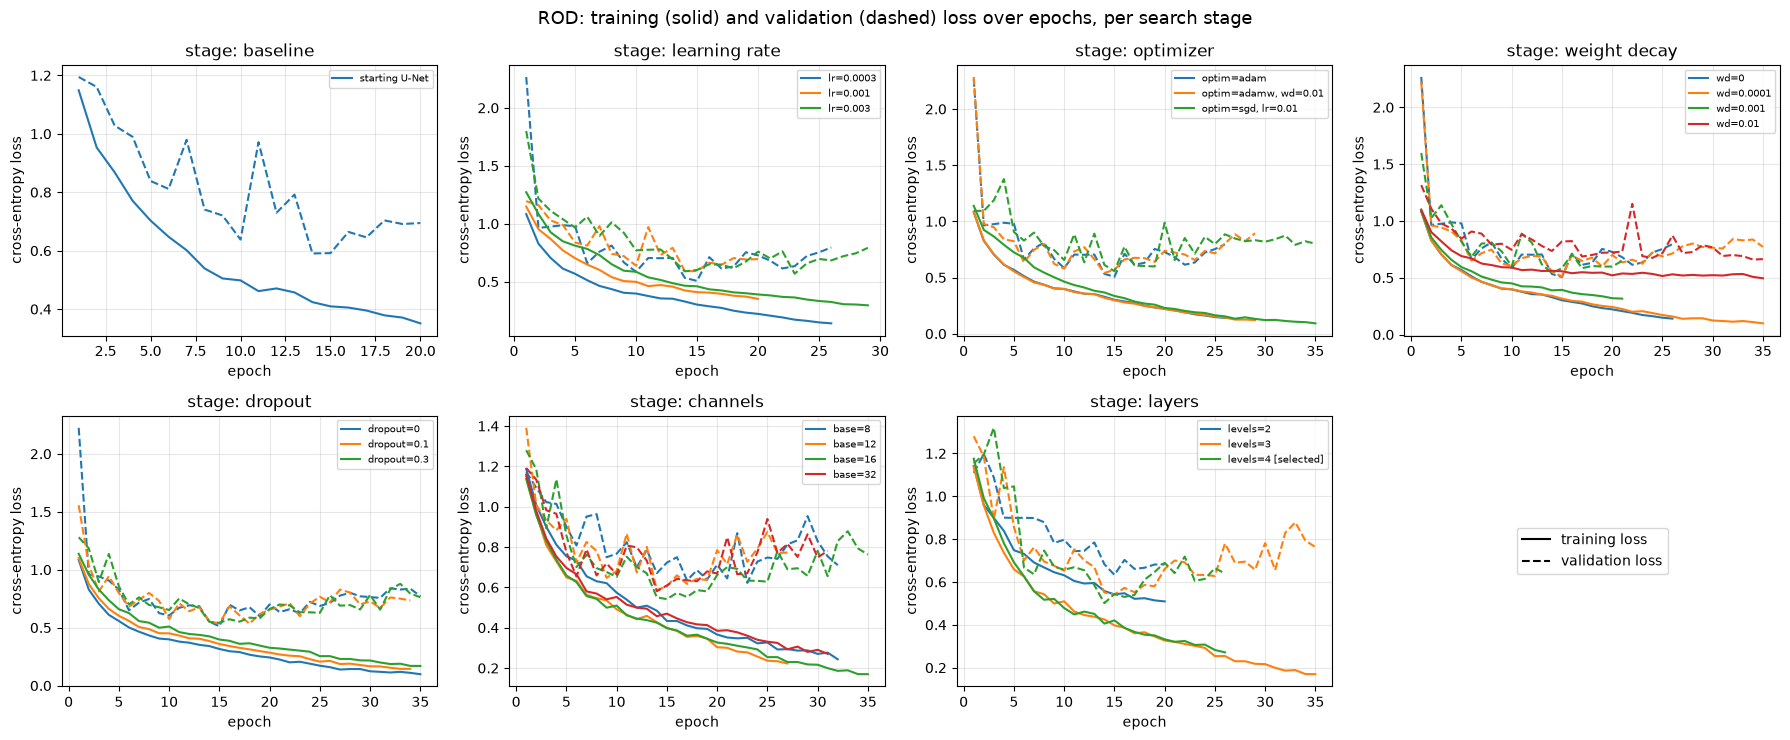

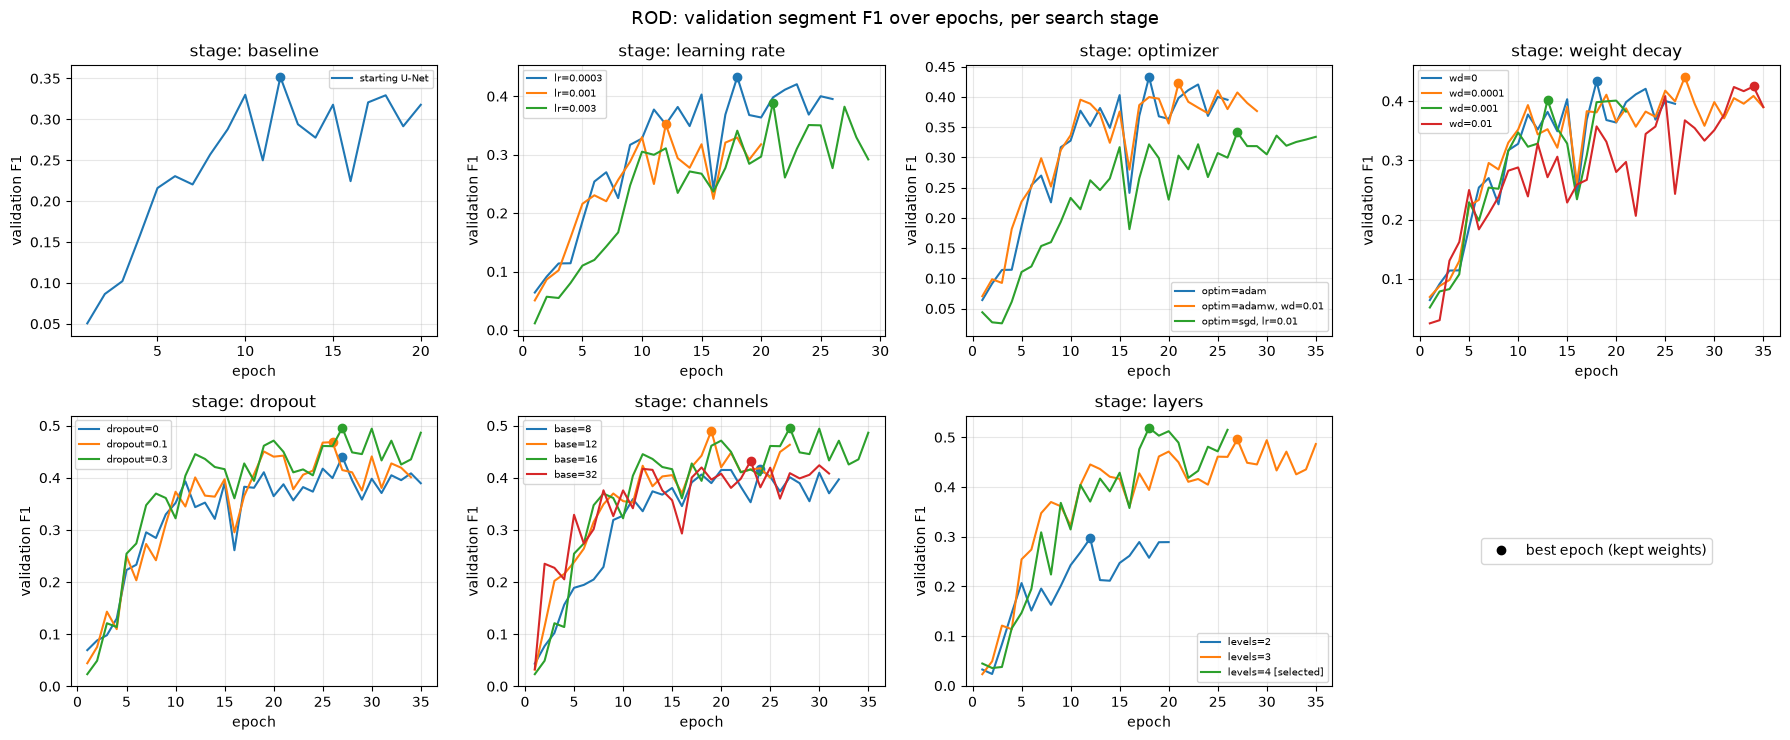

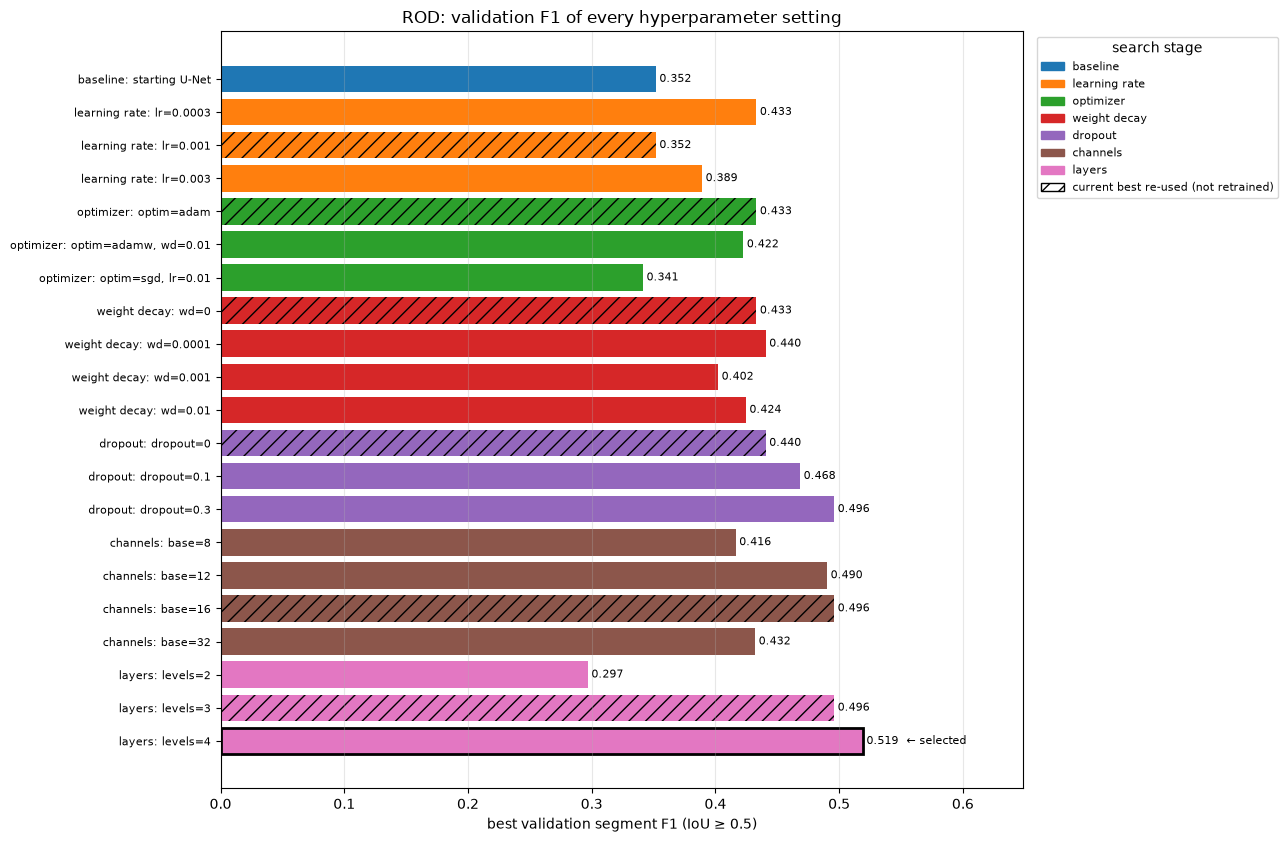

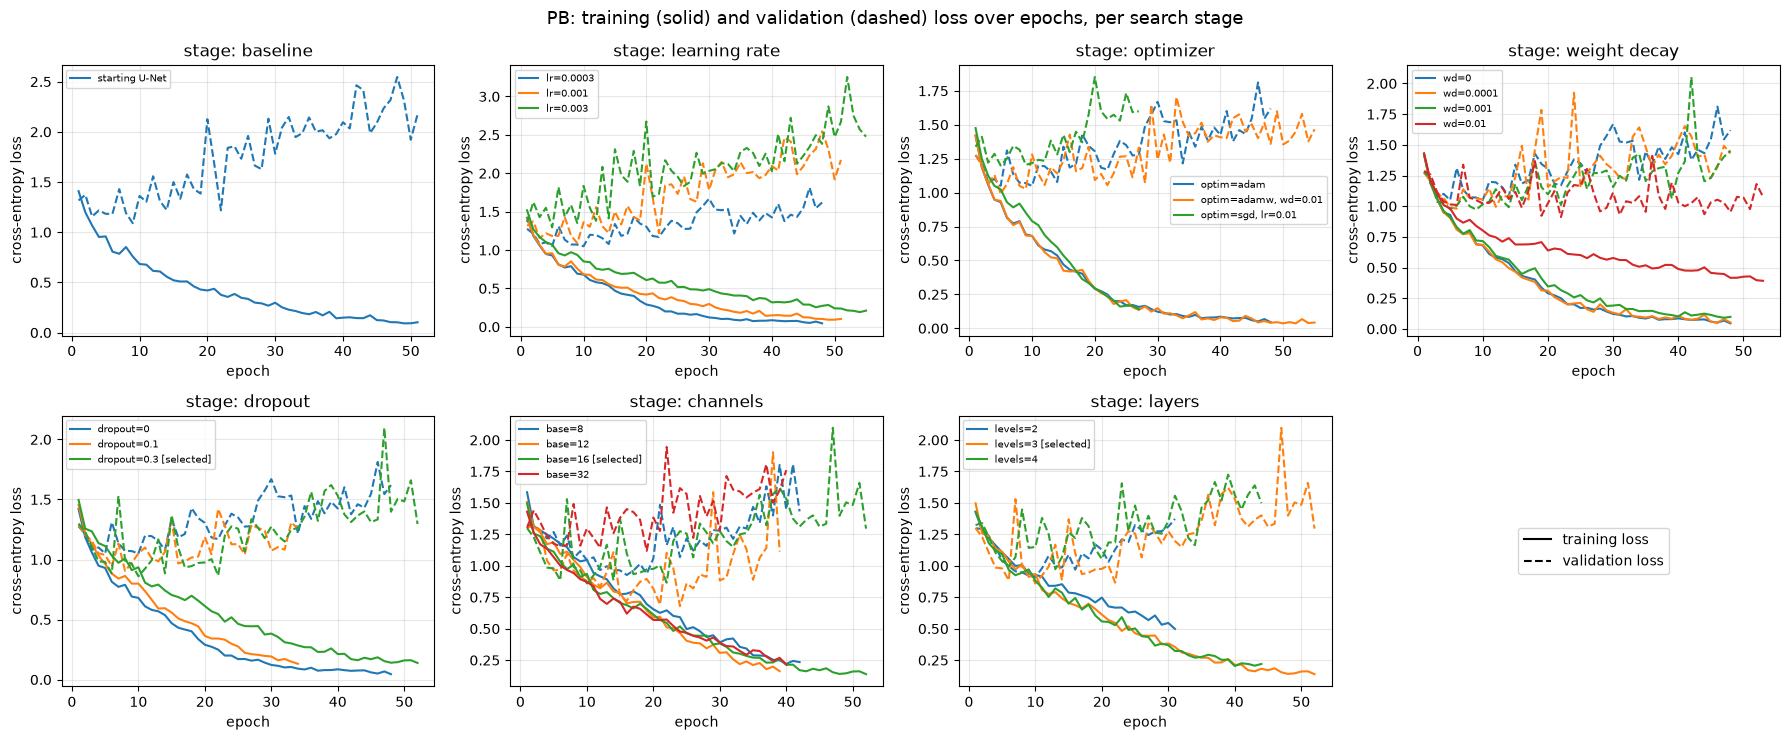

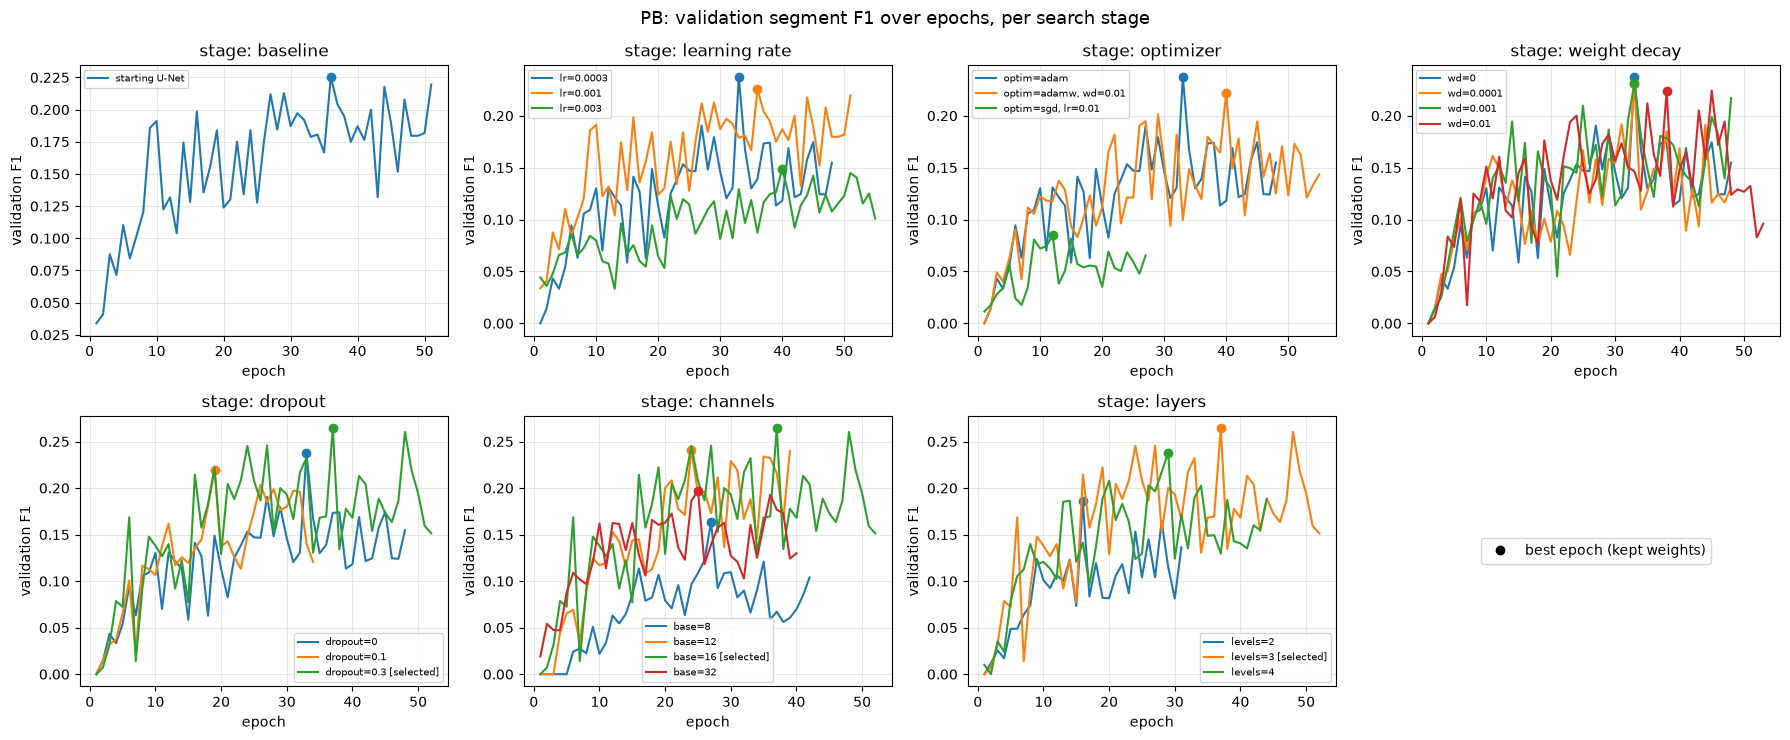

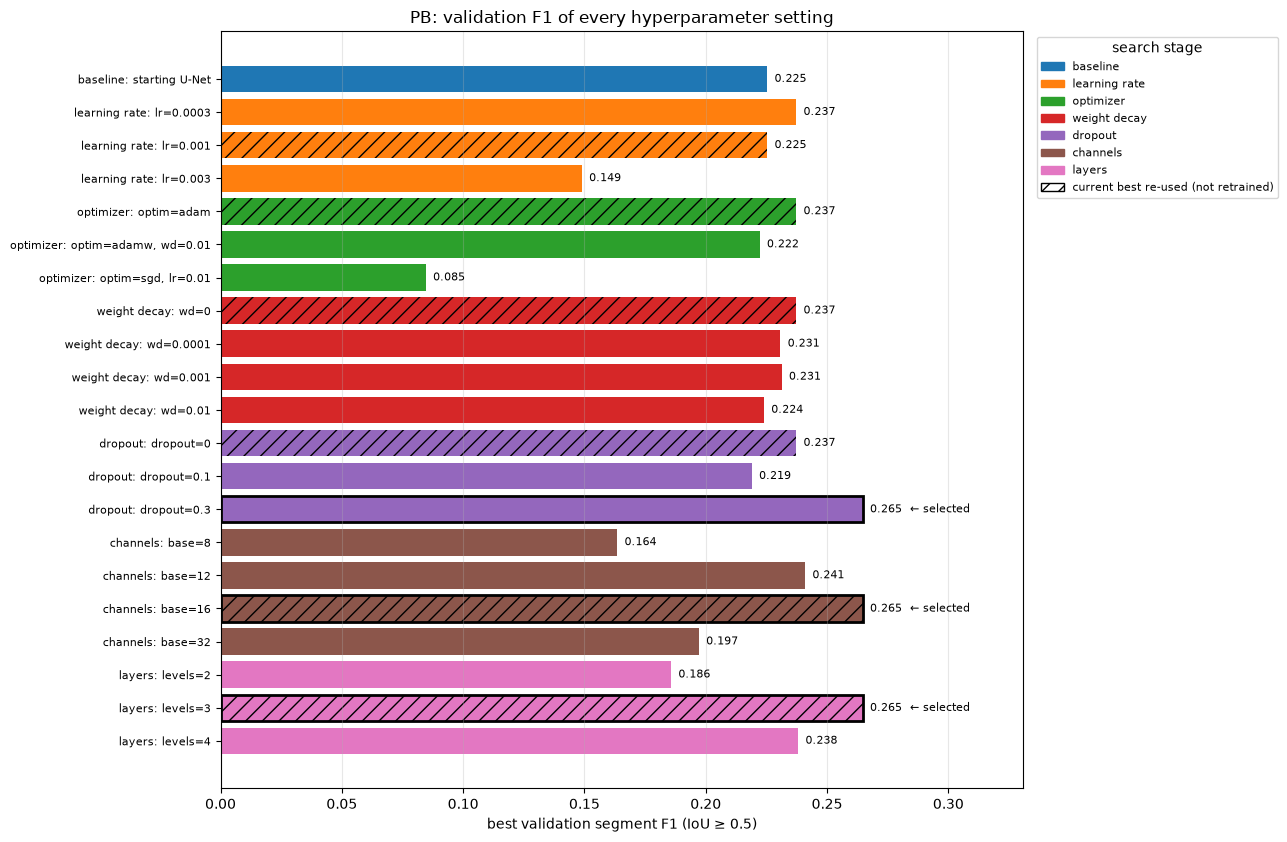

In [14]:
STAGE_NAMES = [s for s, _ in STAGES]

def stage_axes(title):
    fig, axes = plt.subplots(2, 4, figsize=(18, 7.5)); axes = axes.ravel(); axes[-1].axis('off')
    fig.suptitle(title, fontsize=13); return fig, axes

def plot_curves(ds, what):
    fig, axes = stage_axes(f'{ds}: ' + ('training (solid) and validation (dashed) loss' if what == 'loss' else 'validation segment F1')
                           + ' over epochs, per search stage')
    res = RES[ds]
    for ax, stage in zip(axes, STAGE_NAMES):
        sub = res[res['stage'] == stage]
        for k, (_, r) in enumerate(sub.iterrows()):
            h = pd.DataFrame(HIST.get(r['tag'], [])); col = plt.get_cmap('tab10')(k)
            lab = r['changed'] + (' [selected]' if r['tag'] == SELECTED[ds] else '')
            if h.empty:
                ax.plot([], [], color=col, label=f"{lab} ({r['status']})"); continue
            if what == 'loss':
                ax.plot(h['epoch'], h['train_loss'], color=col, label=lab)
                ax.plot(h['epoch'], h['val_loss'], color=col, ls='--')
            else:
                ax.plot(h['epoch'], h['val_F1'], color=col, label=lab)
                ax.plot(r['best_epoch'], r['best_val_F1'], 'o', color=col)
        ax.set(title=f'stage: {stage}', xlabel='epoch', ylabel='cross-entropy loss' if what == 'loss' else 'validation F1')
        ax.grid(alpha=0.3)
        if ax.get_legend_handles_labels()[0]: ax.legend(fontsize=7, loc='best')
    if what == 'loss':
        axes[-1].legend(handles=[Line2D([], [], color='k', label='training loss'), Line2D([], [], color='k', ls='--', label='validation loss')],
                        loc='center', fontsize=10)
    else:
        axes[-1].legend(handles=[Line2D([], [], marker='o', color='k', ls='', label='best epoch (kept weights)')], loc='center', fontsize=10)
    plt.tight_layout(); plt.show()

def plot_comparison(ds):
    res = RES[ds].reset_index(drop=True)
    fig, ax = plt.subplots(figsize=(13, 0.32 * len(res) + 1.8))
    cmap = plt.get_cmap('tab10'); ys = np.arange(len(res))[::-1]
    for y, (_, r) in zip(ys, res.iterrows()):
        col = cmap(STAGE_NAMES.index(r['stage']))
        if r['status'] == 'ok':
            ax.barh(y, r['best_val_F1'], color=col, edgecolor='k' if r['tag'] == SELECTED[ds] else 'none', lw=2,
                    hatch='//' if r['reused_from_earlier_stage'] else None)
            ax.text(r['best_val_F1'] + 0.003, y, f"{r['best_val_F1']:.3f}" + ('  ← selected' if r['tag'] == SELECTED[ds] else ''),
                    va='center', fontsize=8)
        else:
            ax.text(0.003, y, f"{r['status']} (not trained)", va='center', fontsize=8, color='tab:red')
    ax.set_yticks(ys, [f"{r['stage']}: {r['changed']}" for _, r in res.iterrows()], fontsize=8)
    ax.set(xlabel='best validation segment F1 (IoU ≥ 0.5)', title=f'{ds}: validation F1 of every hyperparameter setting',
           xlim=(0, max(0.05, res['best_val_F1'].max() * 1.25)))
    ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=cmap(i), label=s) for i, s in enumerate(STAGE_NAMES)] +
              [plt.Rectangle((0, 0), 1, 1, fc='w', ec='k', hatch='//', label='current best re-used (not retrained)')],
              fontsize=8, loc='upper left', bbox_to_anchor=(1.01, 1), title='search stage')
    ax.grid(axis='x', alpha=0.3); plt.tight_layout(); plt.show()

for ds in RES:
    plot_curves(ds, 'loss'); plot_curves(ds, 'f1'); plot_comparison(ds)

## 11. Selected models on the validation set: per-class results and example predictions

The figures below show what the selected model (chosen on validation F1) does on the **validation** recordings: the per-class precision, recall and F1, and the predicted vs ground-truth ornaments on two example recordings.

ROD selected model, VALIDATION: {'P': 0.415, 'R': 0.694, 'F1': 0.519, 'F1_any': 0.536, 'F1_iou30': 0.567, 'IoU_macro': 0.439, 'IoU_orn': np.float64(0.727), 'IoU_matched': 0.832, 'seg_acc': 0.351, 'boundary_acc': np.float64(0.507), 'frame_acc': np.float64(0.819), 'n_pred': 673, 'n_gt': 402}


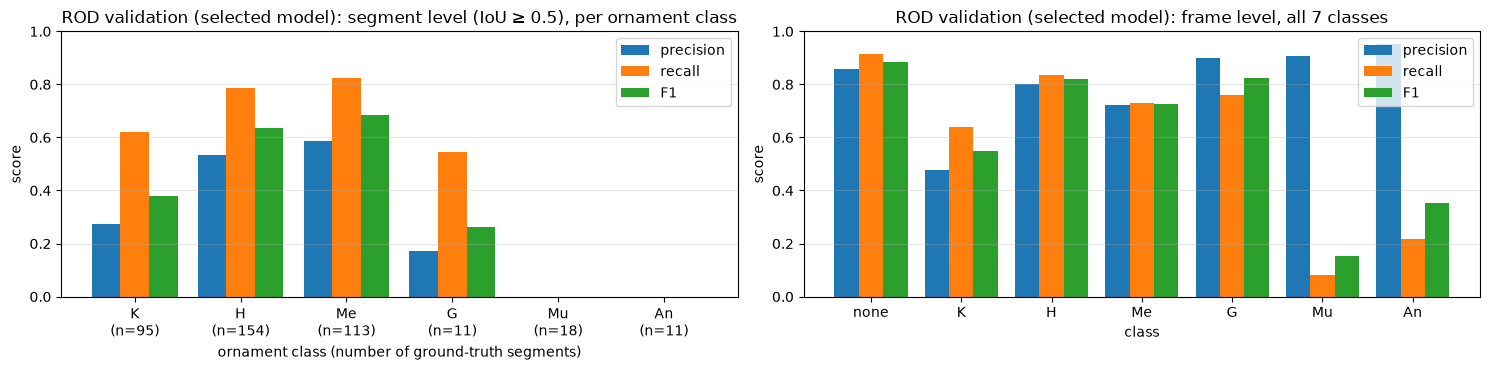

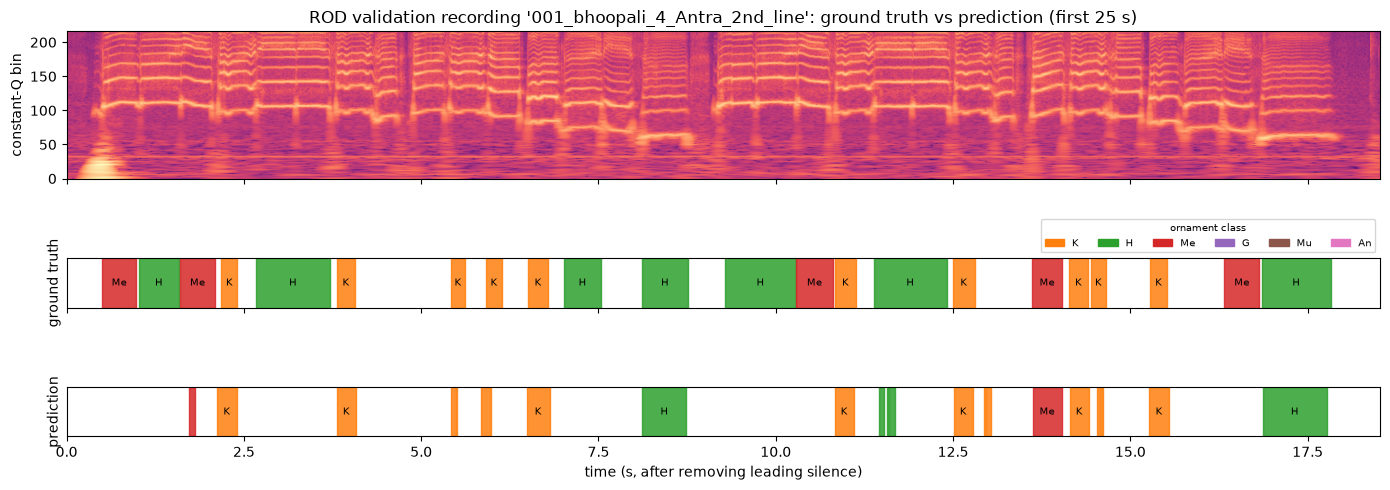

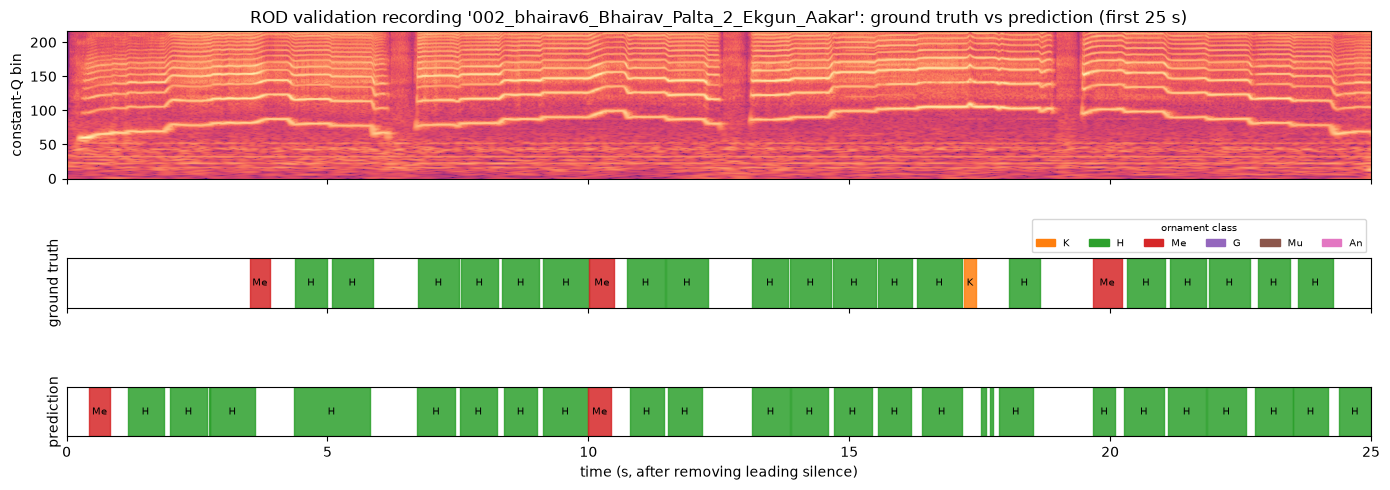

PB selected model, VALIDATION: {'P': 0.209, 'R': 0.36, 'F1': 0.265, 'F1_any': 0.338, 'F1_iou30': 0.309, 'IoU_macro': 0.246, 'IoU_orn': np.float64(0.56), 'IoU_matched': 0.799, 'seg_acc': 0.153, 'boundary_acc': 0.06, 'frame_acc': np.float64(0.753), 'n_pred': 86, 'n_gt': 50}


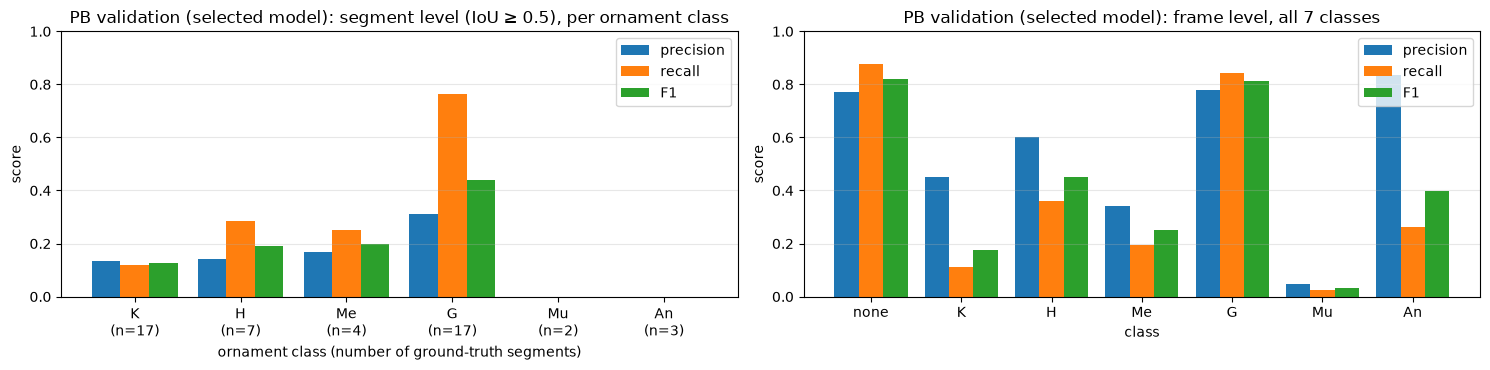

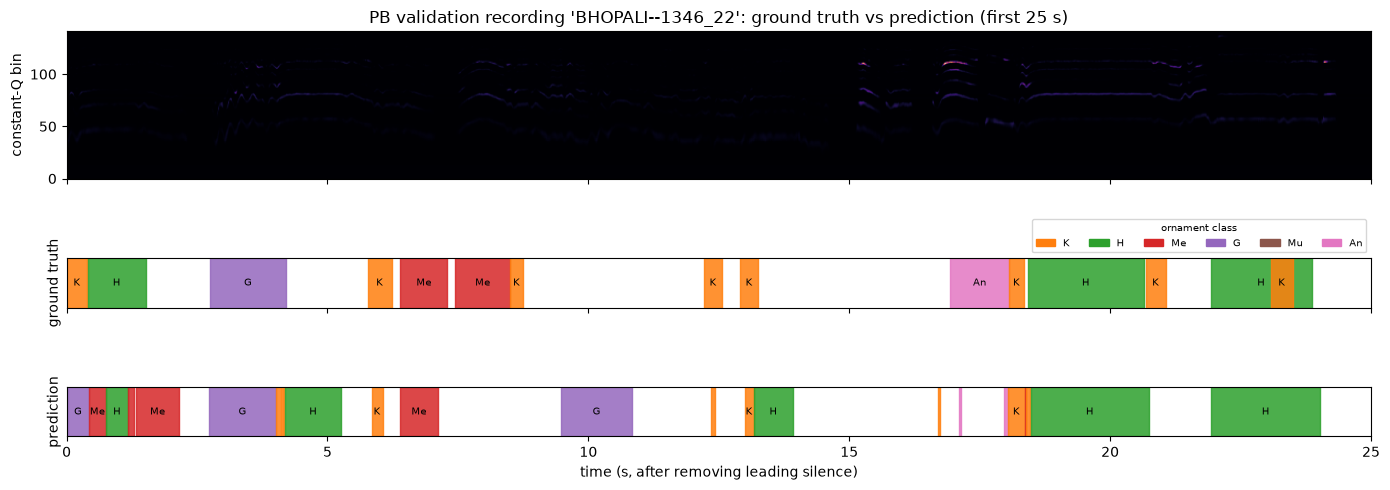

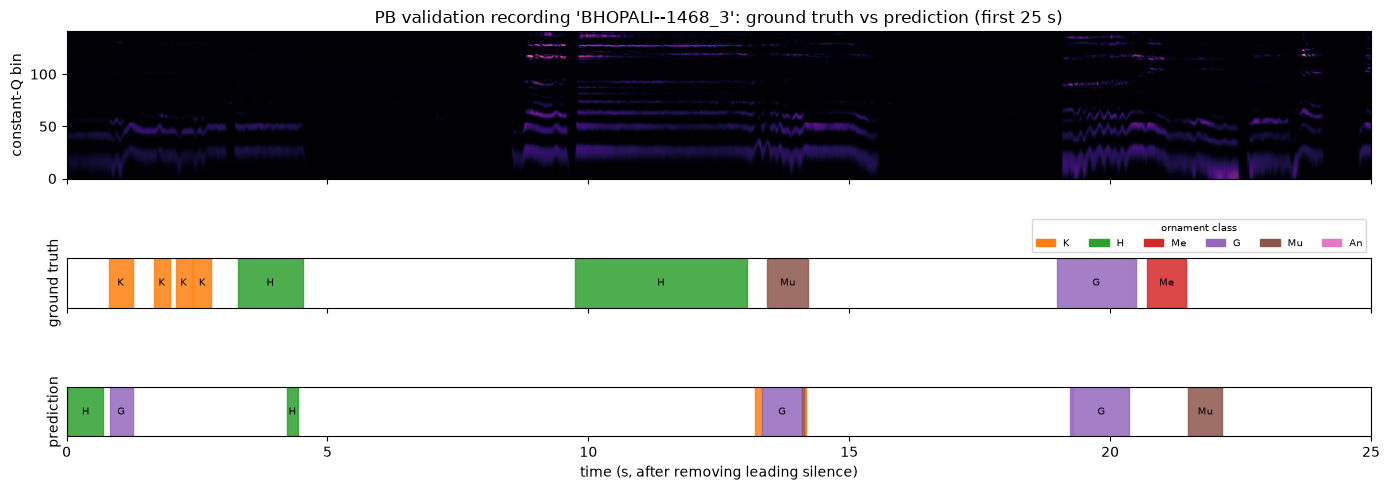

In [15]:
CMAP = plt.get_cmap('tab10')

def plot_per_class(per_class, frame_df, title):
    fig, ax = plt.subplots(1, 2, figsize=(15, 3.8))
    pc = pd.DataFrame(per_class).T; x = np.arange(len(pc)); w = 0.27
    for k, (m, lab) in enumerate((('P', 'precision'), ('R', 'recall'), ('F1', 'F1'))):
        ax[0].bar(x + (k - 1) * w, pc[m], w, label=lab)
    ax[0].set_xticks(x, [f"{c}\n(n={int(pc.loc[c, 'n_gt'])})" for c in pc.index])
    ax[0].set(title=f'{title}: segment level (IoU ≥ 0.5), per ornament class', xlabel='ornament class (number of ground-truth segments)',
              ylabel='score', ylim=(0, 1)); ax[0].legend(); ax[0].grid(axis='y', alpha=0.3)
    x = np.arange(NC)
    for k, m in enumerate(('precision', 'recall', 'F1')):
        ax[1].bar(x + (k - 1) * w, frame_df[m], w, label=m)
    ax[1].set_xticks(x, CLASSES)
    ax[1].set(title=f'{title}: frame level, all 7 classes', xlabel='class', ylabel='score', ylim=(0, 1))
    ax[1].legend(); ax[1].grid(axis='y', alpha=0.3)
    plt.tight_layout(); plt.show()

def show_example(data, labs, t, t0s, dur, title):
    fps = t['fps']; a = int(t0s * fps); b = min(len(t['y']), int((t0s + dur) * fps))
    fig, ax = plt.subplots(3, 1, figsize=(14, 5), sharex=True, gridspec_kw=dict(height_ratios=[3, 1, 1]))
    ax[0].imshow(data.x[t['id']][:, a:b].float().numpy(), origin='lower', aspect='auto', cmap='magma',
                 extent=[a / fps, b / fps, 0, data.n_feat])
    ax[0].set(ylabel='constant-Q bin', title=title)
    for row, (name, segs) in enumerate((('ground truth', [(s, e, C2I[l]) for s, e, l in t['segs'] if l]),
                                        ('prediction', [(s / fps, e / fps, c) for s, e, c in runs(labs[t['id']])]))):
        for s, e, c in segs:
            if e > a / fps and s < b / fps:
                s, e = max(s, a / fps), min(e, b / fps)
                ax[row + 1].axvspan(s, e, color=CMAP(c), alpha=0.85)
                if e - s > 0.15: ax[row + 1].text((s + e) / 2, 0.5, CLASSES[c], ha='center', va='center', fontsize=7)
        ax[row + 1].set(yticks=[], ylabel=name)
    ax[1].legend(handles=[plt.Rectangle((0, 0), 1, 1, color=CMAP(c), label=CLASSES[c]) for c in range(1, NC)],
                 ncol=NC - 1, fontsize=7, loc='upper right', bbox_to_anchor=(1, 1.9), title='ornament class', title_fontsize=7)
    ax[2].set_xlabel('time (s, after removing leading silence)'); plt.tight_layout(); plt.show()

def busiest(tracks, k):
    return sorted(tracks, key=lambda t: -sum(1 for s in t['segs'] if s[2]) / max(t['dur'], 1))[:k]

VAL_LABS = {}
for ds in DATA:
    model = load_model(SELECTED[ds])
    VAL_LABS[ds], _ = predict(model, DATA[ds], DATA[ds].tracks['val'])
    m, pc = evaluate(VAL_LABS[ds], DATA[ds].tracks['val']); fr, _ = frame_report(VAL_LABS[ds], DATA[ds].tracks['val'])
    print(f'{ds} selected model, VALIDATION:', {k: round(v, 3) for k, v in m.items()})
    plot_per_class(pc, fr, f'{ds} validation (selected model)')
    for t in busiest(DATA[ds].tracks['val'], 2):
        show_example(DATA[ds], VAL_LABS[ds], t, 0.0, 25.0, f"{ds} validation recording '{t['id']}': ground truth vs prediction (first 25 s)")
    del model; torch.cuda.empty_cache()

## 12. Final test evaluation (held-out test recordings)

The models were chosen above using validation F1 only. Here each selected model is run **once** on the test recordings. These numbers are only reported; nothing is changed afterwards. The best model of each dataset is saved as `rod_koopman/unet_seg/best_unet_<dataset>.pt`, together with its settings and normalisation statistics.

In [16]:
TEST, TEST_LABS = {}, {}
for ds in DATA:
    ck = torch.load(RUNS / f'{SELECTED[ds]}.pt', map_location='cpu', weights_only=False)
    torch.save(ck, OUT / f'best_unet_{ds}.pt')
    model = load_model(SELECTED[ds])
    TEST_LABS[ds], test_loss = predict(model, DATA[ds], DATA[ds].tracks['test'])
    m, pc = evaluate(TEST_LABS[ds], DATA[ds].tracks['test']); fr, cm = frame_report(TEST_LABS[ds], DATA[ds].tracks['test'])
    vm, _ = evaluate(VAL_LABS[ds], DATA[ds].tracks['val'])
    TEST[ds] = dict(tag=SELECTED[ds], cfg=ck['cfg'], val=vm, test=dict(m, loss=test_loss), test_per_class_segment=pc,
                    test_per_class_frame=fr.to_dict('index'), test_confusion_frames=cm.tolist())
    del model; torch.cuda.empty_cache()

cols = ['P', 'R', 'F1', 'IoU_macro', 'IoU_orn', 'IoU_matched', 'seg_acc', 'F1_any', 'F1_iou30', 'boundary_acc', 'frame_acc', 'n_pred', 'n_gt']
tab = pd.DataFrame({f'{ds} {sp}': TEST[ds][k] for ds in TEST for sp, k in (('validation', 'val'), ('test', 'test'))}).T[cols]
tab = tab.rename(columns=dict(P='precision', R='recall', IoU_macro='IoU (macro, per class)', IoU_orn='IoU (ornament vs none)',
                              IoU_matched='IoU (matched segments)', seg_acc='segment-level accuracy'))
print('Selected models:', {ds: TEST[ds]['tag'] for ds in TEST}); display(tab.round(3))
tab.to_csv(OUT / 'test_results.csv')
for ds in TEST:
    print(f'{ds} TEST, per ornament class (segment level, IoU >= 0.5)'); display(pd.DataFrame(TEST[ds]['test_per_class_segment']).T.round(3))
    print(f'{ds} TEST, per class (frame level)'); display(pd.DataFrame(TEST[ds]['test_per_class_frame']).T.round(3))
json.dump(TEST, open(OUT / 'final_results.json', 'w'), indent=1, default=float)
print('saved:', OUT / 'test_results.csv', '|', OUT / 'final_results.json', '|', [str(OUT / f'best_unet_{ds}.pt') for ds in TEST])

Selected models: {'ROD': 'ROD_lr0.0003_adam_wd0.0001_do0.3_b16_L4', 'PB': 'PB_lr0.0003_adam_wd0_do0.3_b16_L3'}


,precision,recall,F1,"IoU (macro, per class)",IoU (ornament vs none),IoU (matched segments),segment-level accuracy,F1_any,F1_iou30,boundary_acc,frame_acc,n_pred,n_gt
ROD validation,0.415,0.694,0.519,0.439,0.727,0.832,0.351,0.536,0.567,0.507,0.819,673.0,402.0
ROD test,0.344,0.661,0.453,0.381,0.697,0.822,0.293,0.468,0.513,0.466,0.823,1770.0,921.0
PB validation,0.209,0.360,0.265,0.246,0.560,0.799,0.153,0.338,0.309,0.060,0.753,86.0,50.0
PB test,0.175,0.304,0.222,0.239,0.504,0.748,0.125,0.286,0.286,0.058,0.696,120.0,69.0


ROD TEST, per ornament class (segment level, IoU >= 0.5)


,P,R,F1,IoU,n_gt,n_pred
K,0.242,0.568,0.340,0.297,241.0,565.0
H,0.458,0.789,0.580,0.712,360.0,620.0
Me,0.382,0.691,0.492,0.501,256.0,463.0
G,0.136,0.458,0.210,0.697,24.0,81.0
Mu,0.000,0.000,0.000,0.030,24.0,9.0
An,0.000,0.000,0.000,0.050,16.0,32.0


ROD TEST, per class (frame level)


,precision,recall,F1,IoU,gt_frames,pred_frames
none,0.892,0.884,0.888,0.799,114924.0,113959.0
K,0.380,0.575,0.458,0.297,6140.0,9293.0
H,0.795,0.872,0.832,0.712,39067.0,42892.0
Me,0.660,0.675,0.668,0.501,15024.0,15364.0
G,0.863,0.784,0.822,0.697,4615.0,4190.0
Mu,0.268,0.033,0.059,0.030,1271.0,157.0
An,0.678,0.052,0.096,0.050,5211.0,397.0


PB TEST, per ornament class (segment level, IoU >= 0.5)


,P,R,F1,IoU,n_gt,n_pred
K,0.000,0.000,0.000,0.027,19.0,17.0
H,0.233,0.476,0.312,0.403,21.0,43.0
Me,0.143,0.357,0.204,0.178,14.0,35.0
G,0.375,0.857,0.522,0.467,7.0,16.0
Mu,0.000,0.000,0.000,0.000,6.0,3.0
An,0.000,0.000,0.000,0.357,2.0,6.0


PB TEST, per class (frame level)


,precision,recall,F1,IoU,gt_frames,pred_frames
none,0.751,0.892,0.815,0.688,5959.0,7081.0
K,0.095,0.037,0.053,0.027,377.0,147.0
H,0.622,0.534,0.575,0.403,2269.0,1946.0
Me,0.444,0.229,0.302,0.178,716.0,369.0
G,0.599,0.679,0.636,0.467,473.0,536.0
Mu,0.000,0.000,0.000,0.000,246.0,22.0
An,0.737,0.409,0.526,0.357,137.0,76.0


saved: C:\Users\YOGESH KRISHNA\Desktop\smai-project\rod_koopman\unet_seg\test_results.csv | C:\Users\YOGESH KRISHNA\Desktop\smai-project\rod_koopman\unet_seg\final_results.json | ['C:\\Users\\YOGESH KRISHNA\\Desktop\\smai-project\\rod_koopman\\unet_seg\\best_unet_ROD.pt', 'C:\\Users\\YOGESH KRISHNA\\Desktop\\smai-project\\rod_koopman\\unet_seg\\best_unet_PB.pt']


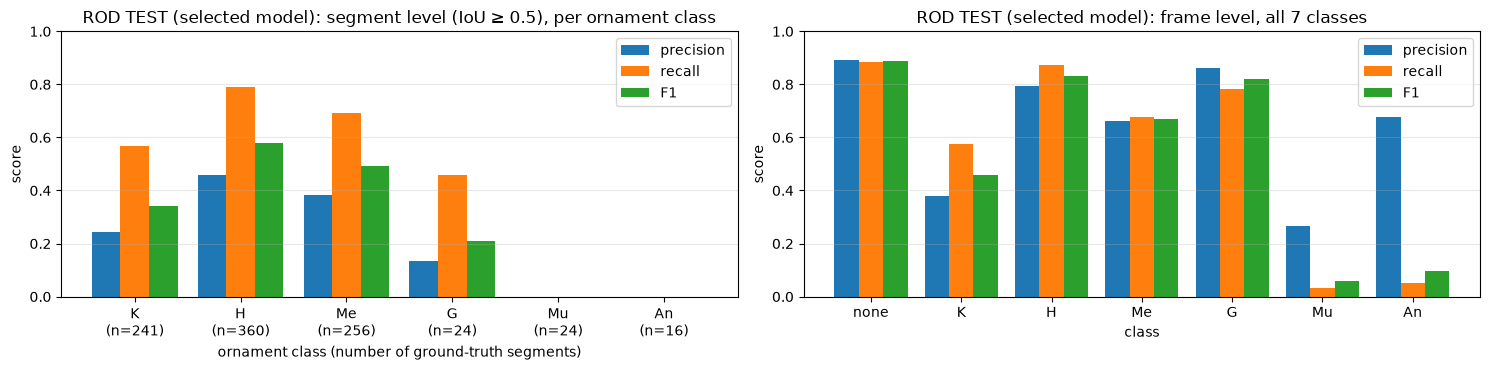

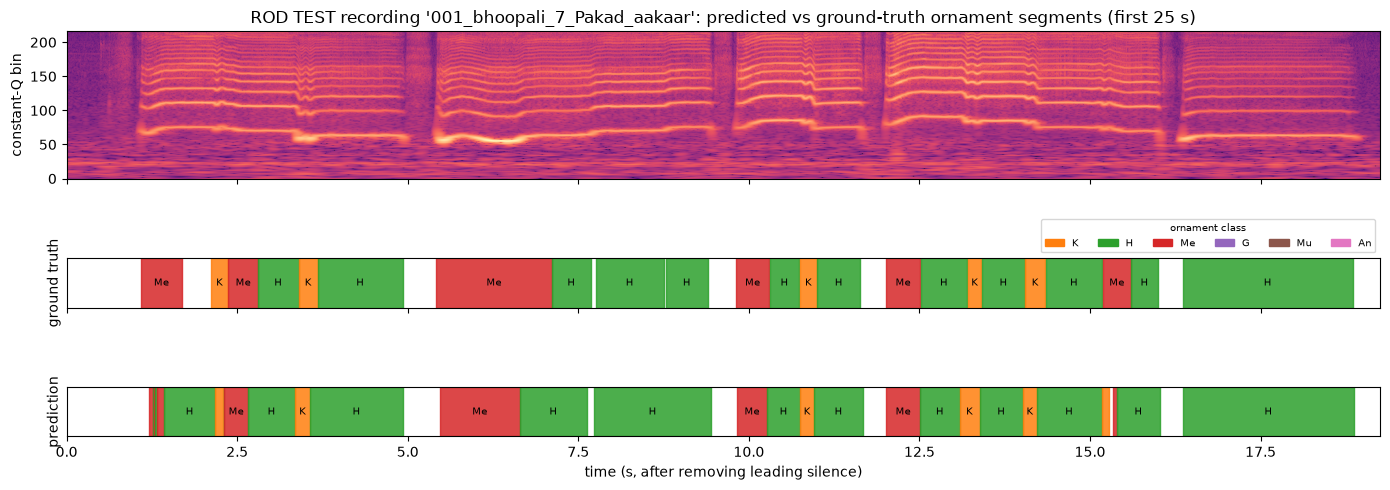

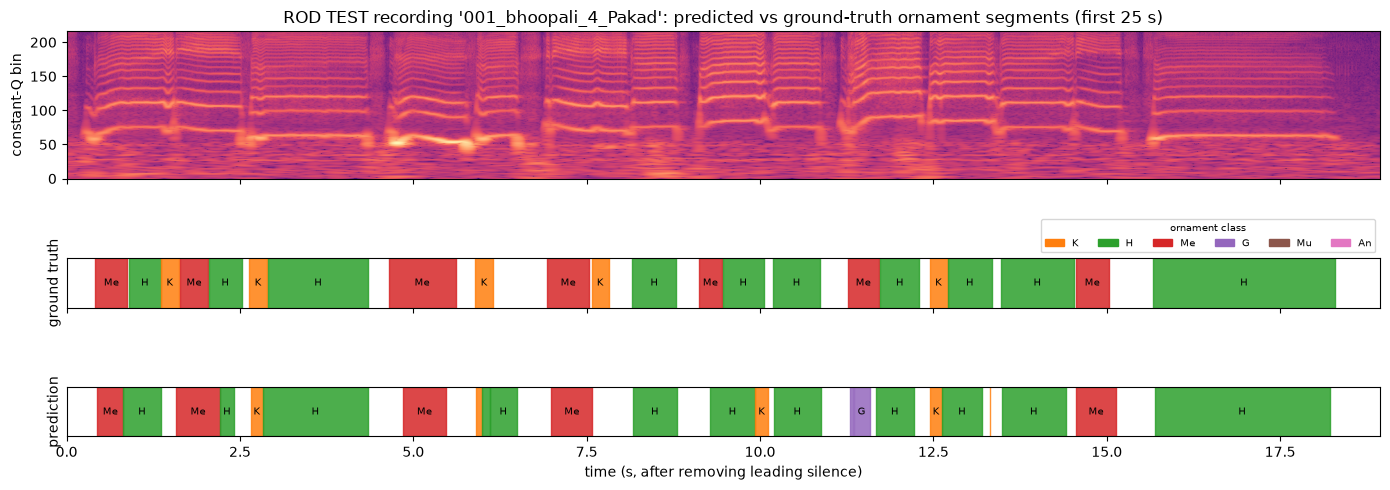

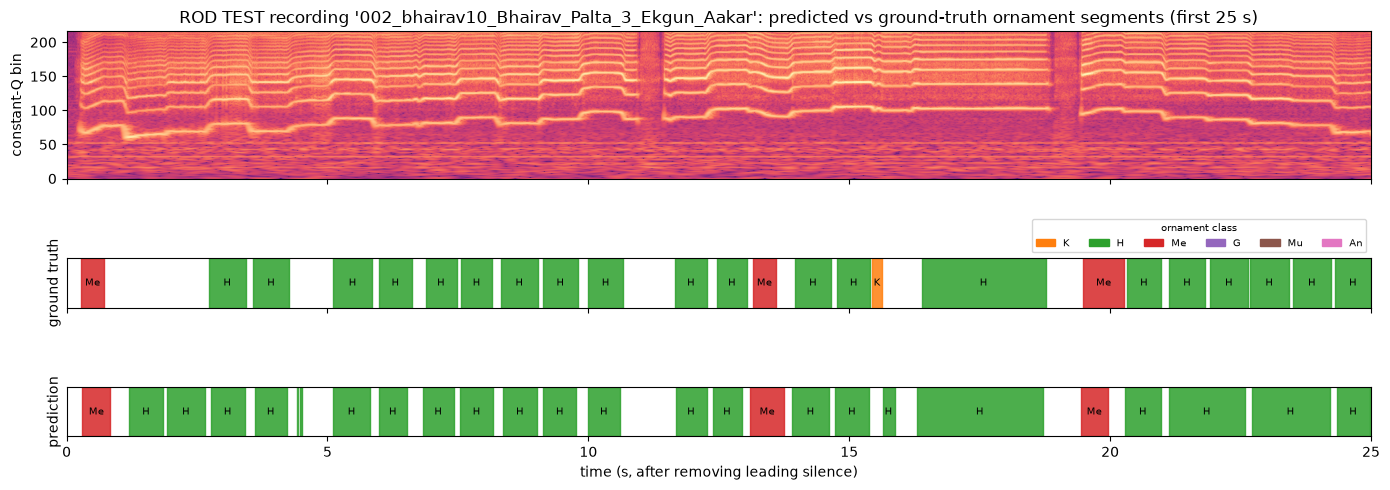

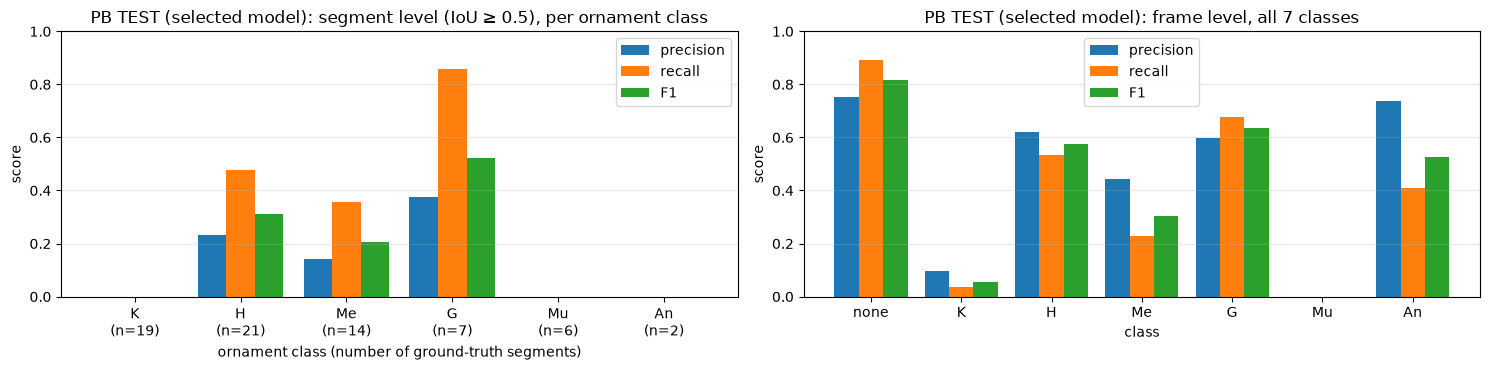

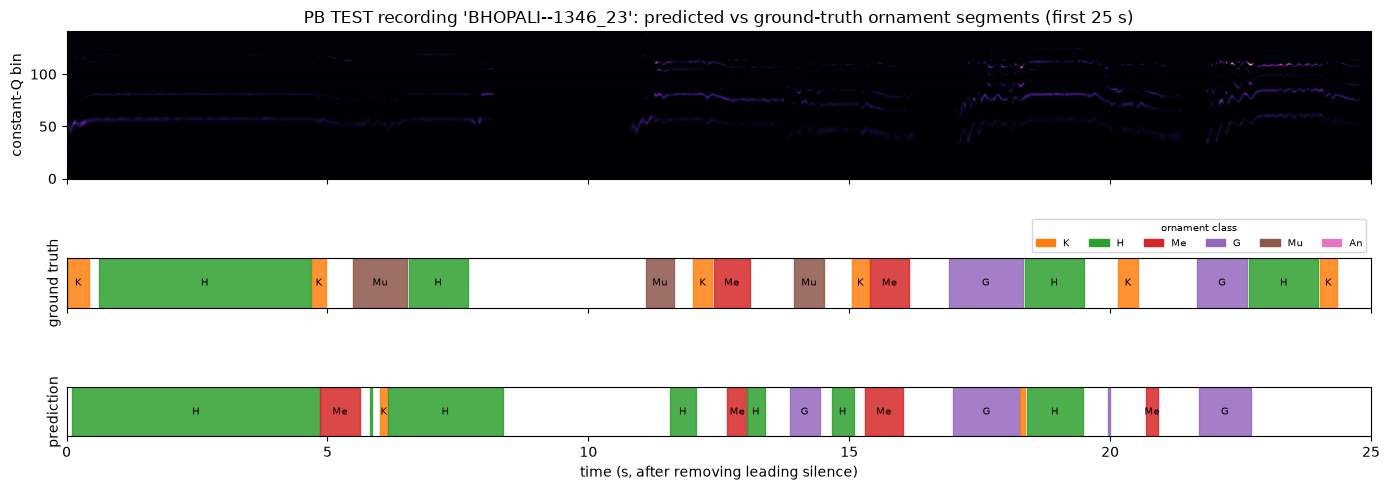

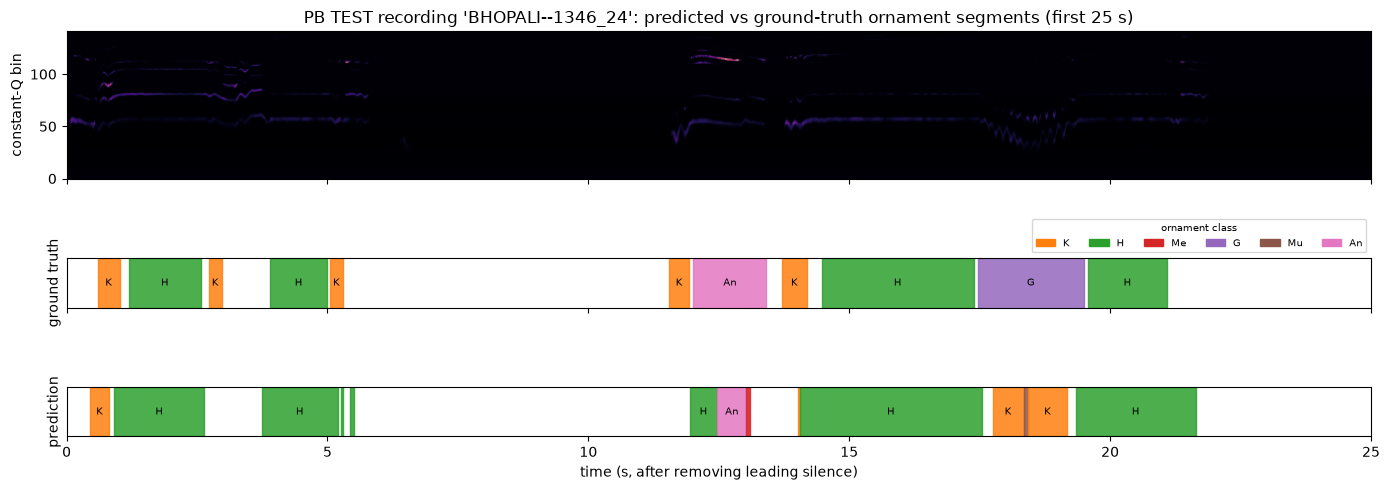

In [17]:
for ds in TEST:
    plot_per_class(TEST[ds]['test_per_class_segment'], pd.DataFrame(TEST[ds]['test_per_class_frame']).T, f'{ds} TEST (selected model)')
    for t in busiest(DATA[ds].tracks['test'], 3 if ds == 'ROD' else 2):
        show_example(DATA[ds], TEST_LABS[ds], t, 0.0, 25.0, f"{ds} TEST recording '{t['id']}': predicted vs ground-truth ornament segments (first 25 s)")

## Notes

* **Data**: only the saved cache is used, with the original splits and all 7 classes. The only preprocessing is removing silence at the start and end of each recording (aligned for features, labels and segment times), then per-bin normalisation from the training split.
* **Model and training**: a 2D U-Net on the full CQT of each recording, plain cross-entropy without class weights, no augmentation, one whole recording per step.
* **Selection**: each hyperparameter group was changed in turn, and only changes that raised validation F1 were kept. The test set was used once, at the very end.
* **Saved outputs** (`rod_koopman/unet_seg/`): `runs/*.json` and `runs/*.pt` (every experiment), `search_results_*.csv` (the comparison tables), `selected_models.json`, `best_unet_ROD.pt` / `best_unet_PB.pt`, `test_results.csv` and `final_results.json`.
* **Memory / failures**: configurations that needed more than the 4 GB of GPU memory were run with spill into shared system RAM and are flagged `uses_shared_memory` (correct, but slower). Out-of-memory errors and other failed experiments are marked in the search tables and the comparison plot with their error message. They were not shortened or retried with crops.